**<center style="font-size:4em;">Data exploration notebook</center>**

# To-Dos:
- speichern der Grafiken in einem Ordner mit einer bestimmten Namenskonvention um nicht unzählige Kopien zu haben
- Zellen umbauen sodass die Importe immer da sind wo sie auch gebraucht werden
- Berechnen von sby_need aus calls auch in Funktion auslagern, um Copy-Paste zu vermeiden
- Prediction-Teil ggf auslagern in eine andere Datei

- LSTM ermöglichen zusätzliche Features bei der Prediction zu nutzen
- mehr und sinnvolles Feature Engineering für das Datum einbauen
- die nicht predictablen Ausreißer bei call und sby_need untersuchen nachschauen
- Modellansatz aufstellen, der Ausreißer ignoriert (ggf beim Result df oder schon beim Training entfernen)

# Initialization

## Loading data

In [1]:
import pandas as pd

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

In [2]:
df.dtypes

date         object
n_sick        int64
calls       float64
n_duty        int64
n_sby         int64
sby_need    float64
dafted      float64
dtype: object

## Initial data adaptions

In [3]:
# Convert date string column to datetime column
df['date'] = pd.to_datetime(df['date'])

# Add numeric date 
df['unix_ts_date'] = df['date'].astype(int) // 10**9

# Make date to index 
df.set_index('date', inplace=True)

# Set daily frequency
df = df.asfreq('d')

# Correlation matrix of data

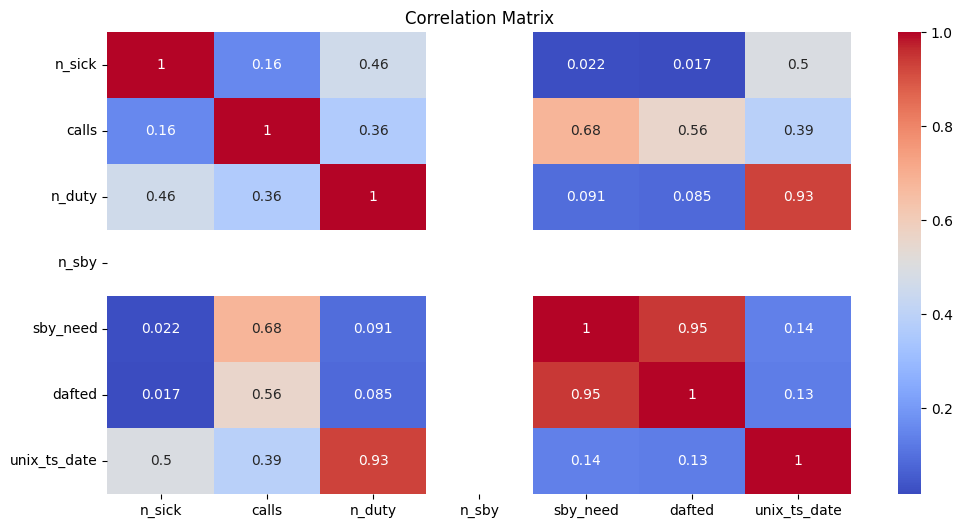

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Plot all columns over time

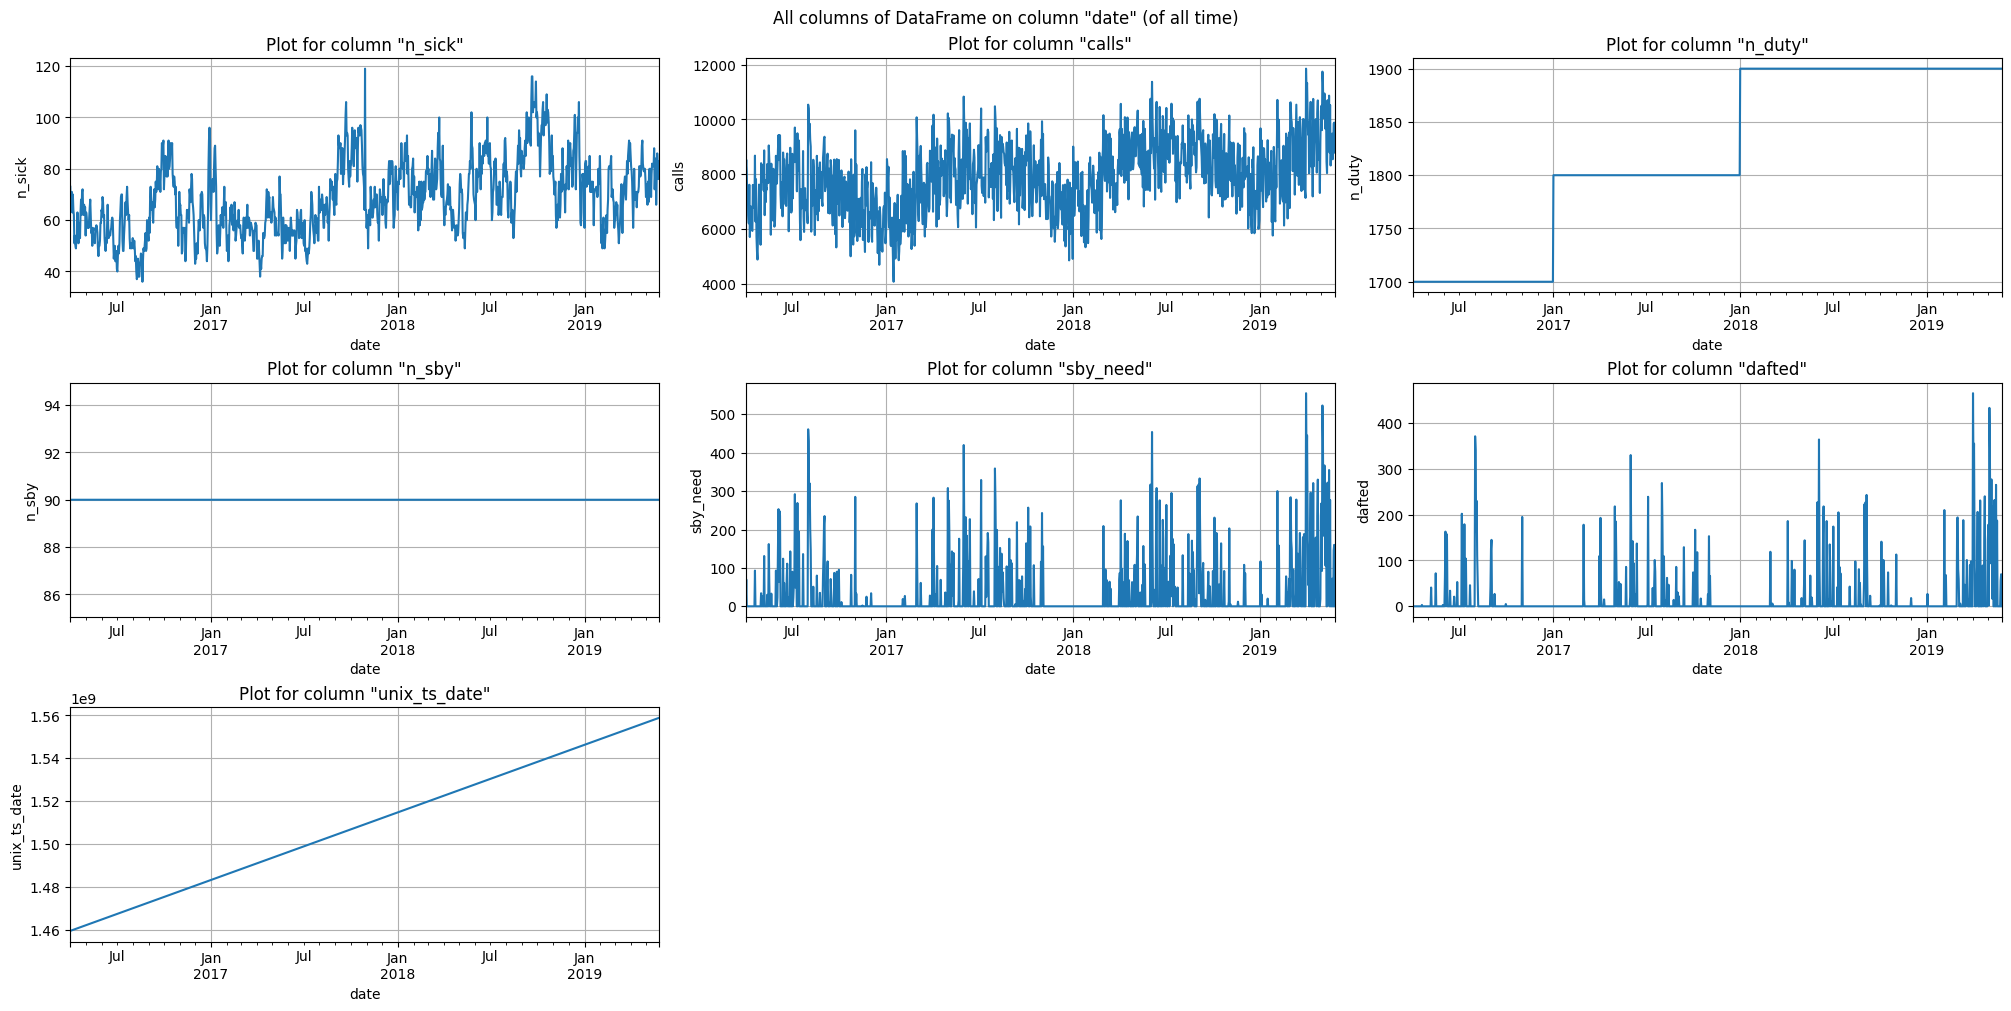

In [5]:
import math
from typing import List, Optional

def plot_columns_on_index_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    if num_columns > 2:
        num_rows = math.ceil(math.sqrt(num_columns))
        num_cols = math.ceil(num_columns / num_rows)
    else:
        num_rows = 1
        num_cols = num_columns

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 10), constrained_layout=True)
    fig.suptitle(f'All columns of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        if num_columns > 2:
            row = i // num_cols
            col = i % num_cols
            ax = axes[row, col]
        else:
            ax = axes[i] if num_columns > 1 else axes
        if df[column].dtype == bool:
            df[column].astype(int).plot(ax=ax, title=f'Plot for column "{column}" (bool)')
        else:
            df[column].plot(ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)
        ax.grid()

    # Leere Subplots entfernen
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

plot_columns_on_index_in_subplots(df, annotation="of all time")

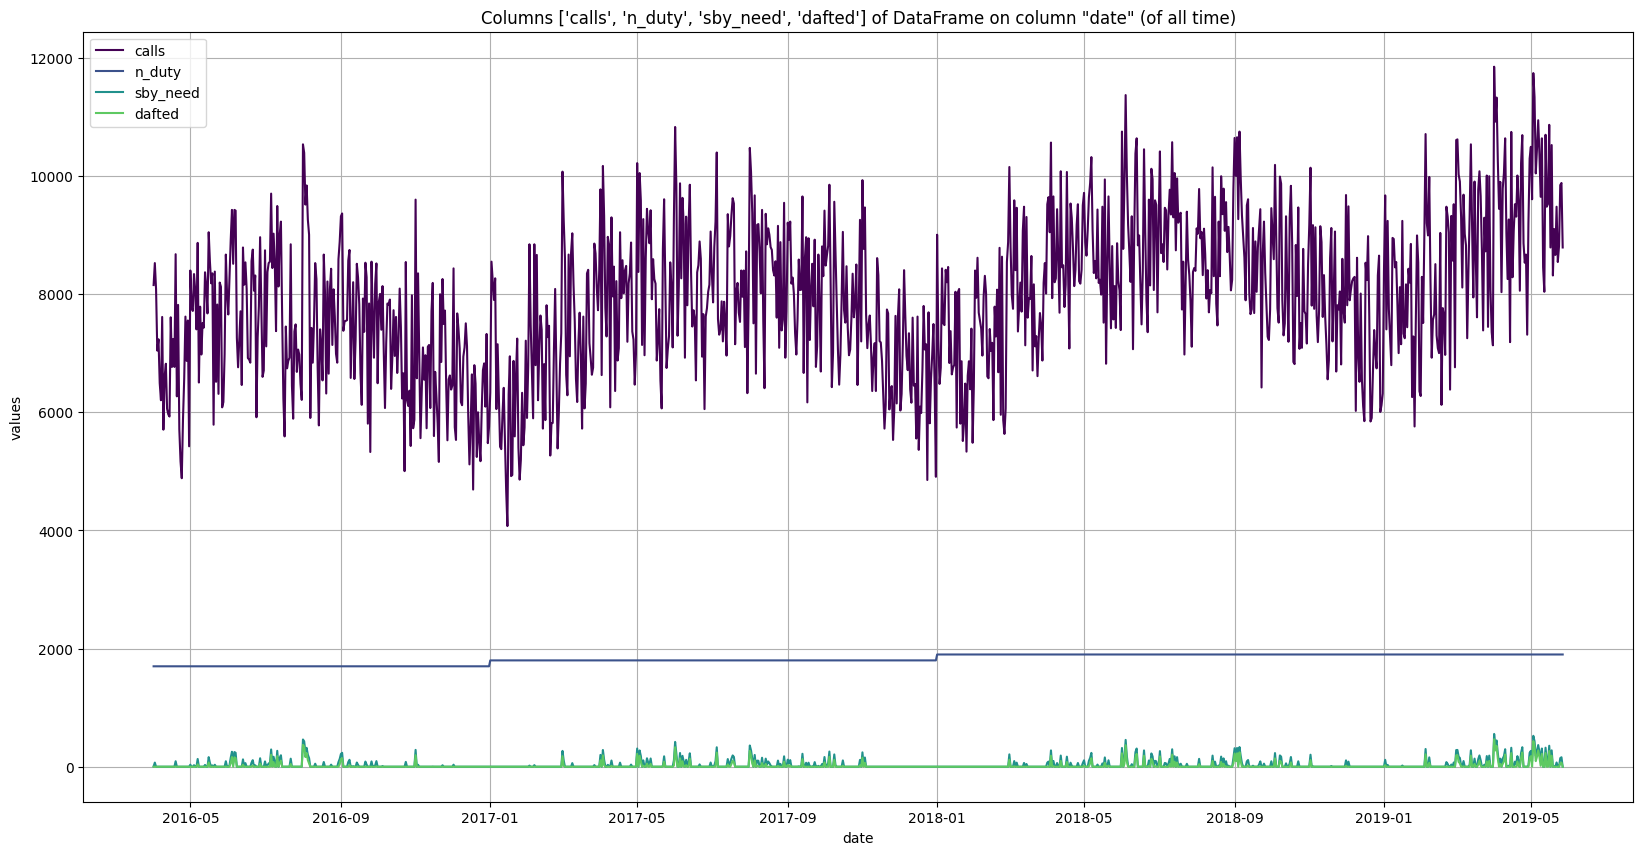

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import List, Optional

def plot_columns_on_index(df: pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:
    if columns is None:
        columns = df.columns
    
    plt.figure(figsize=(20, 10))
    
    num_columns = len(columns)
    color_map = plt.get_cmap('viridis')
    
    max_value = df[columns].select_dtypes(include=[float, int]).max().max()
    
    for i, column in enumerate(columns):
        if column in df.columns:
            color = color_map(i / num_columns)
            if df[column].dtype == bool:
                plt.plot(df.index, df[column].astype(int) * max_value, label=column + " (bool)", color=color, linestyle="dotted")
            else:
                plt.plot(df.index, df[column], label=column, color=color)
        else:
            print(f'Column "{column}" not found in DataFrame')
    
    plt.xlabel(df.index.name)
    plt.ylabel('values')
    plt.title(f'Columns {columns} of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""))
    plt.legend()

    plt.grid()
    plt.show()

# Beispielaufruf
plot_columns_on_index(df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation="of all time")


## Plot columns over one year

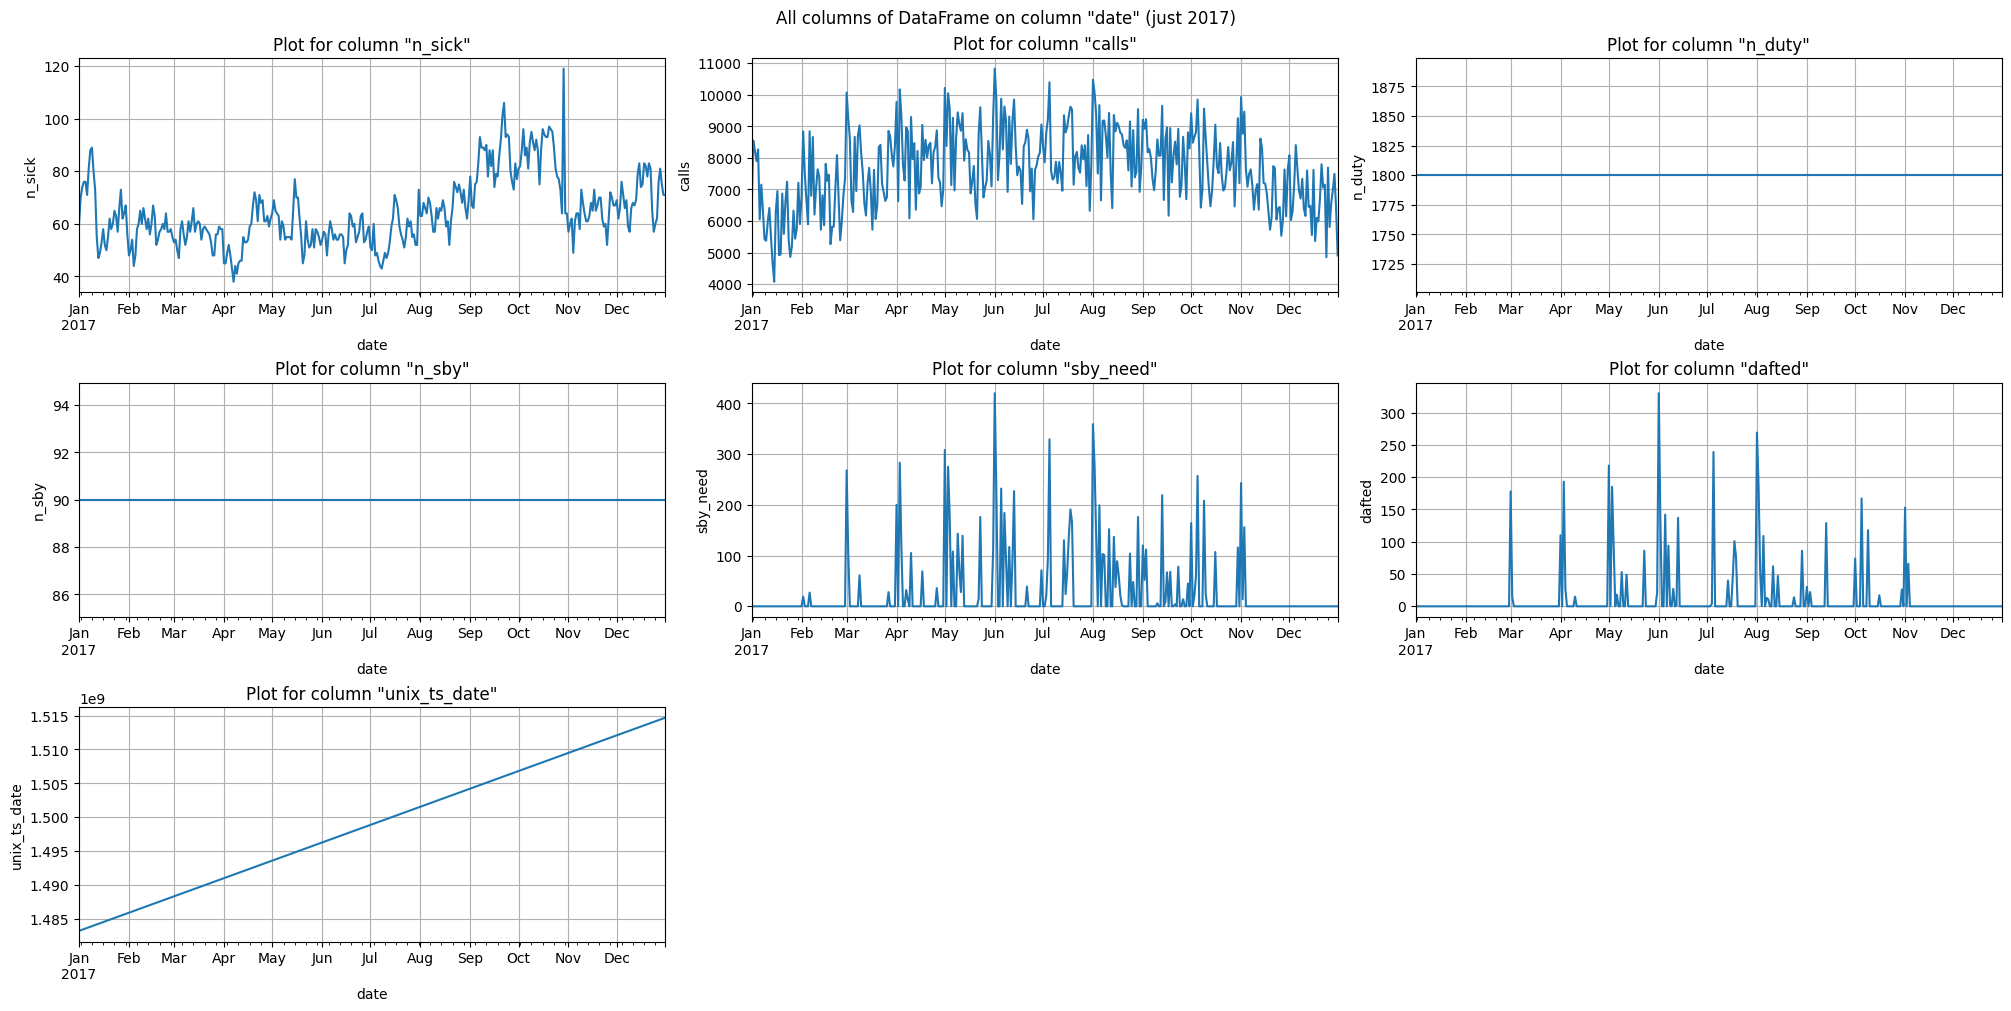

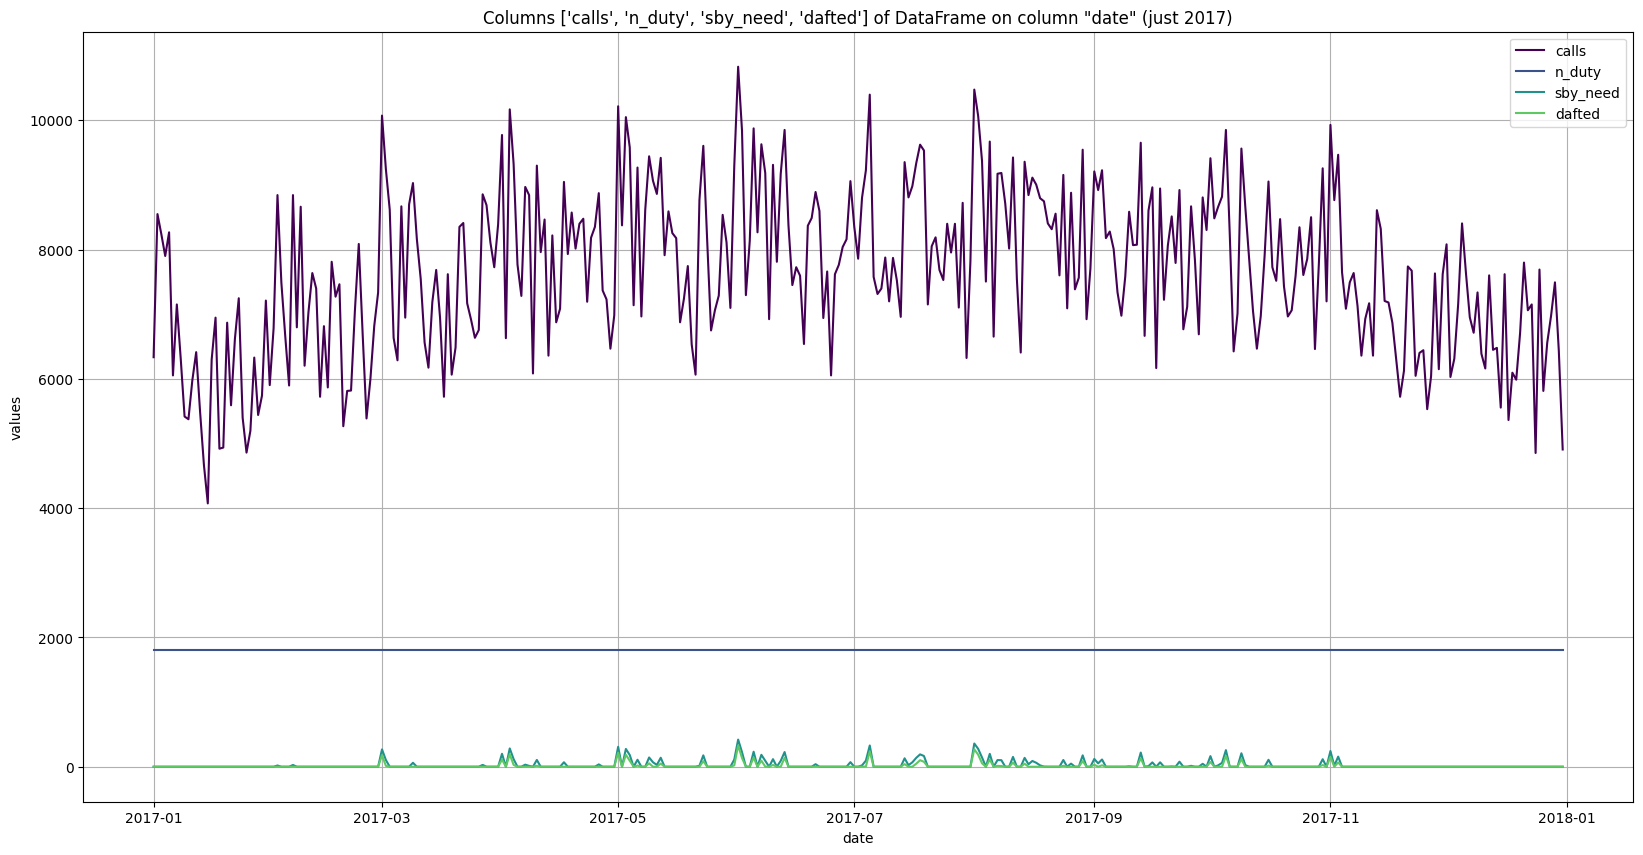

In [7]:
selected_year = 2017

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

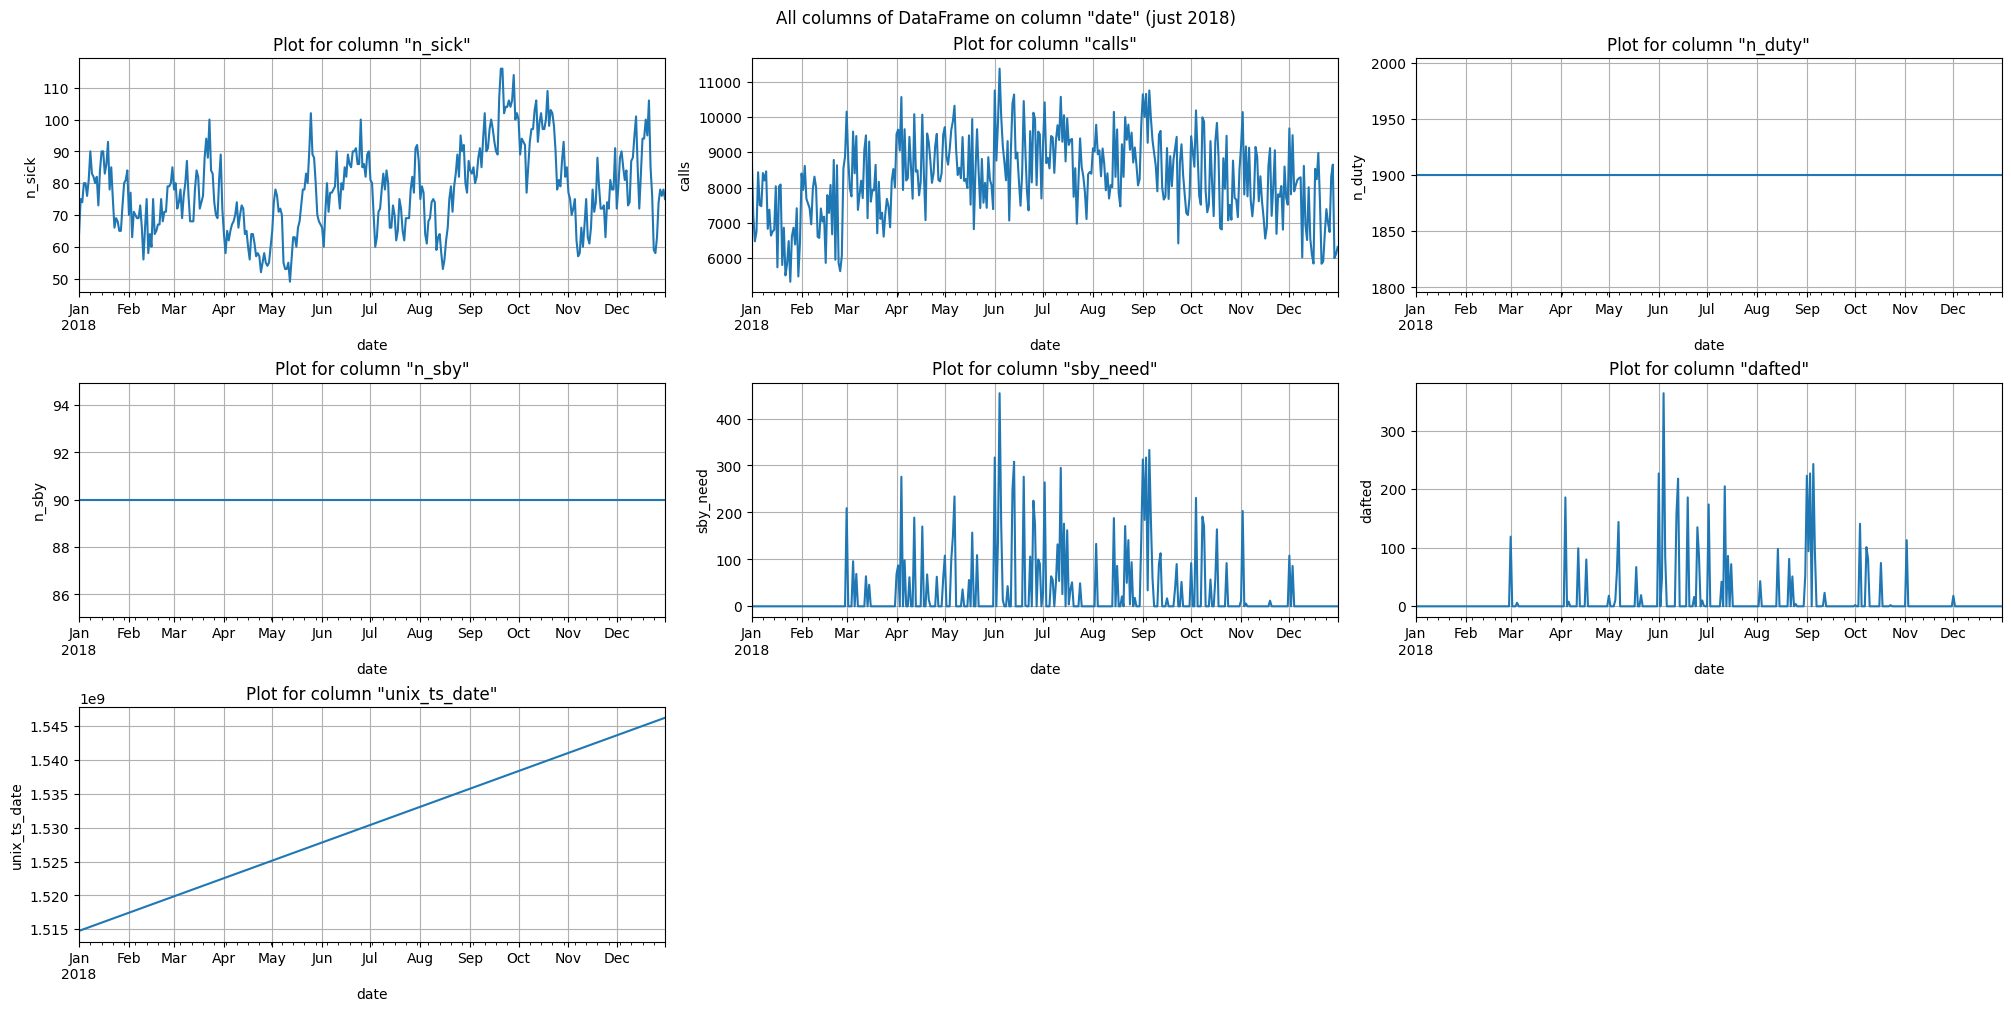

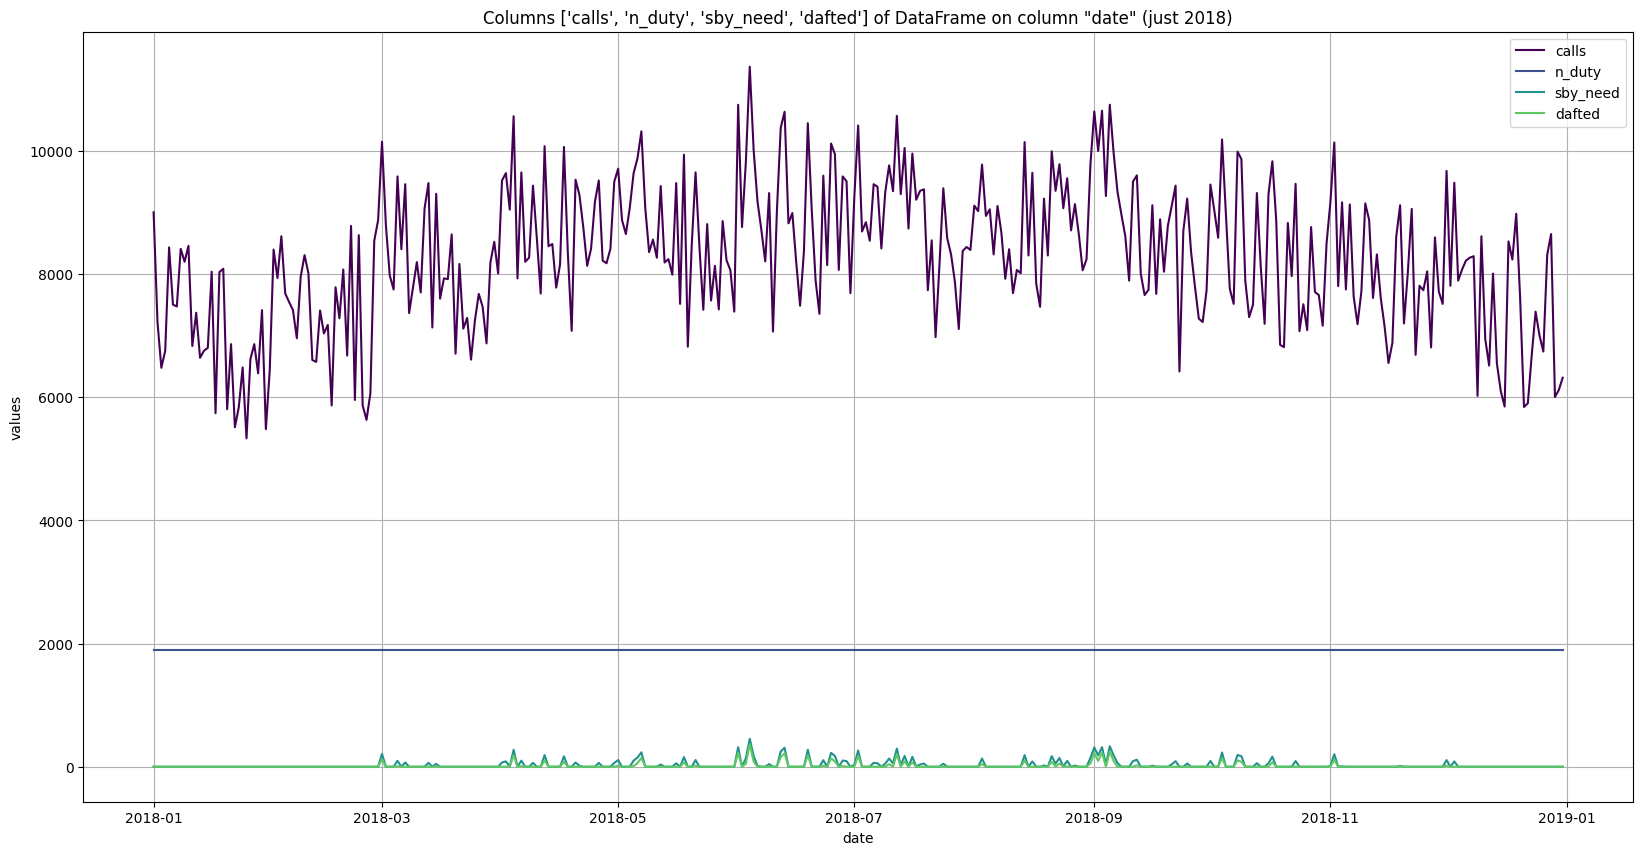

In [8]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

## Correlation matrix for one year

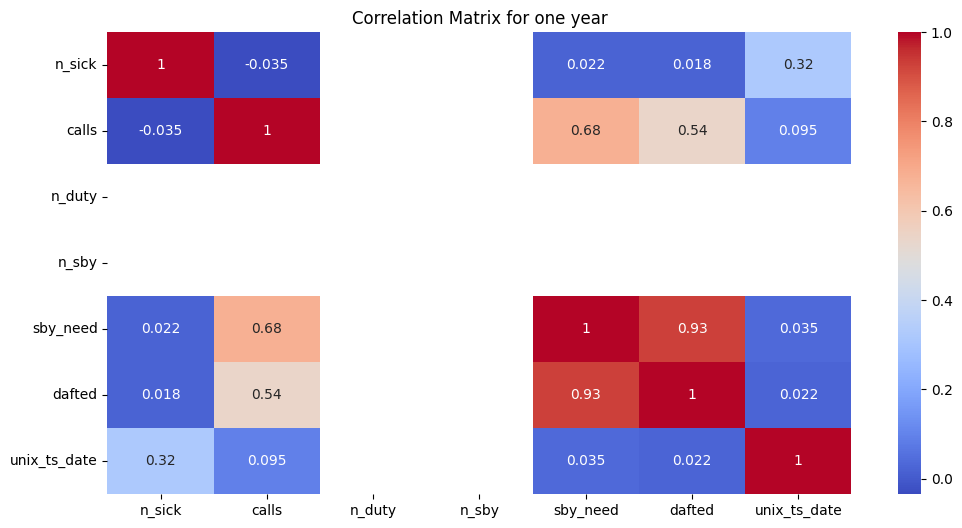

In [9]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plt.figure(figsize=(12, 6))
sns.heatmap(one_year_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for one year')
plt.show()

## Findings

Erkenntnisse: 
- n_duty steigt am Anfang jeden Jahrs fix und wird nicht wieder gesenkt
- calls hat ein wiederkehrendes Muster. Es geht im Winter runter und beim Sommer hoch. Hat aber starke Ausschläge 
- ähnlich bei sby_need und logischerweise bei dafted. Im Winter nichts und sonst gelegengtlich

# Experimental data cleansing

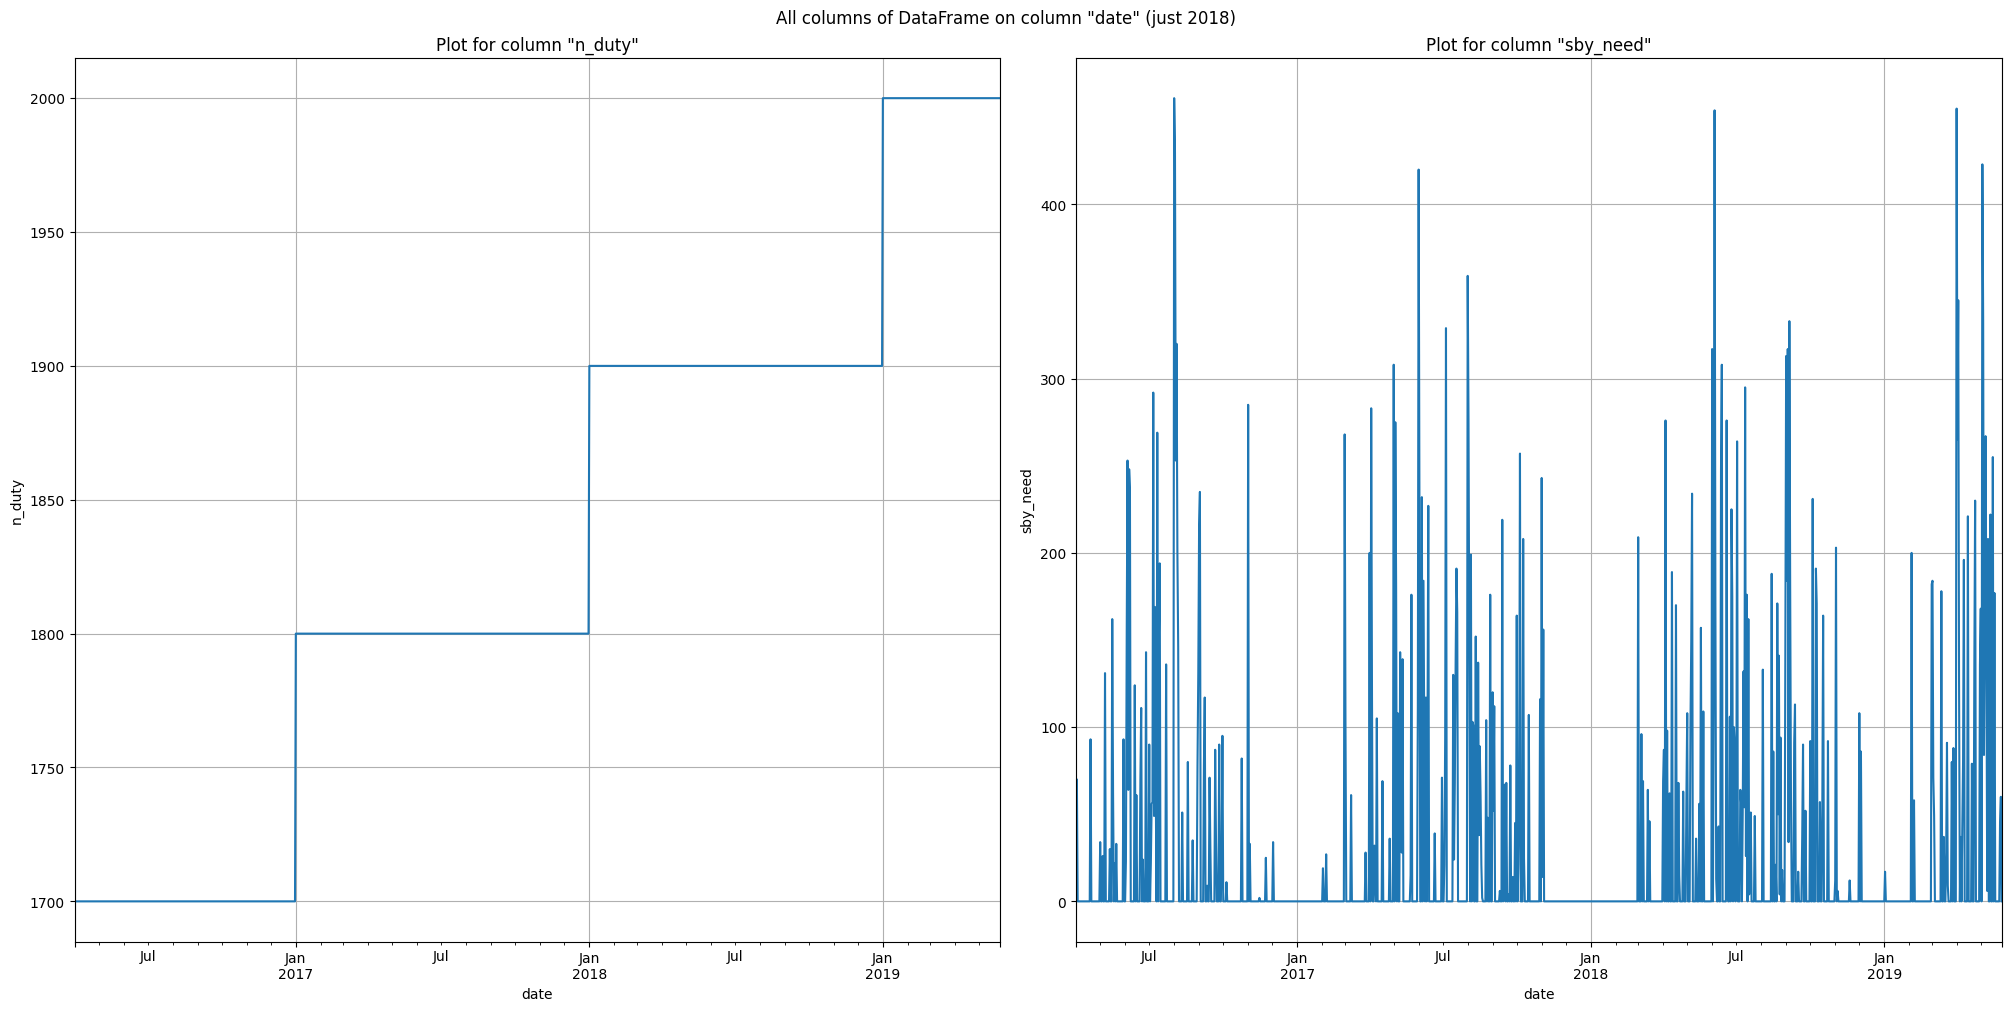

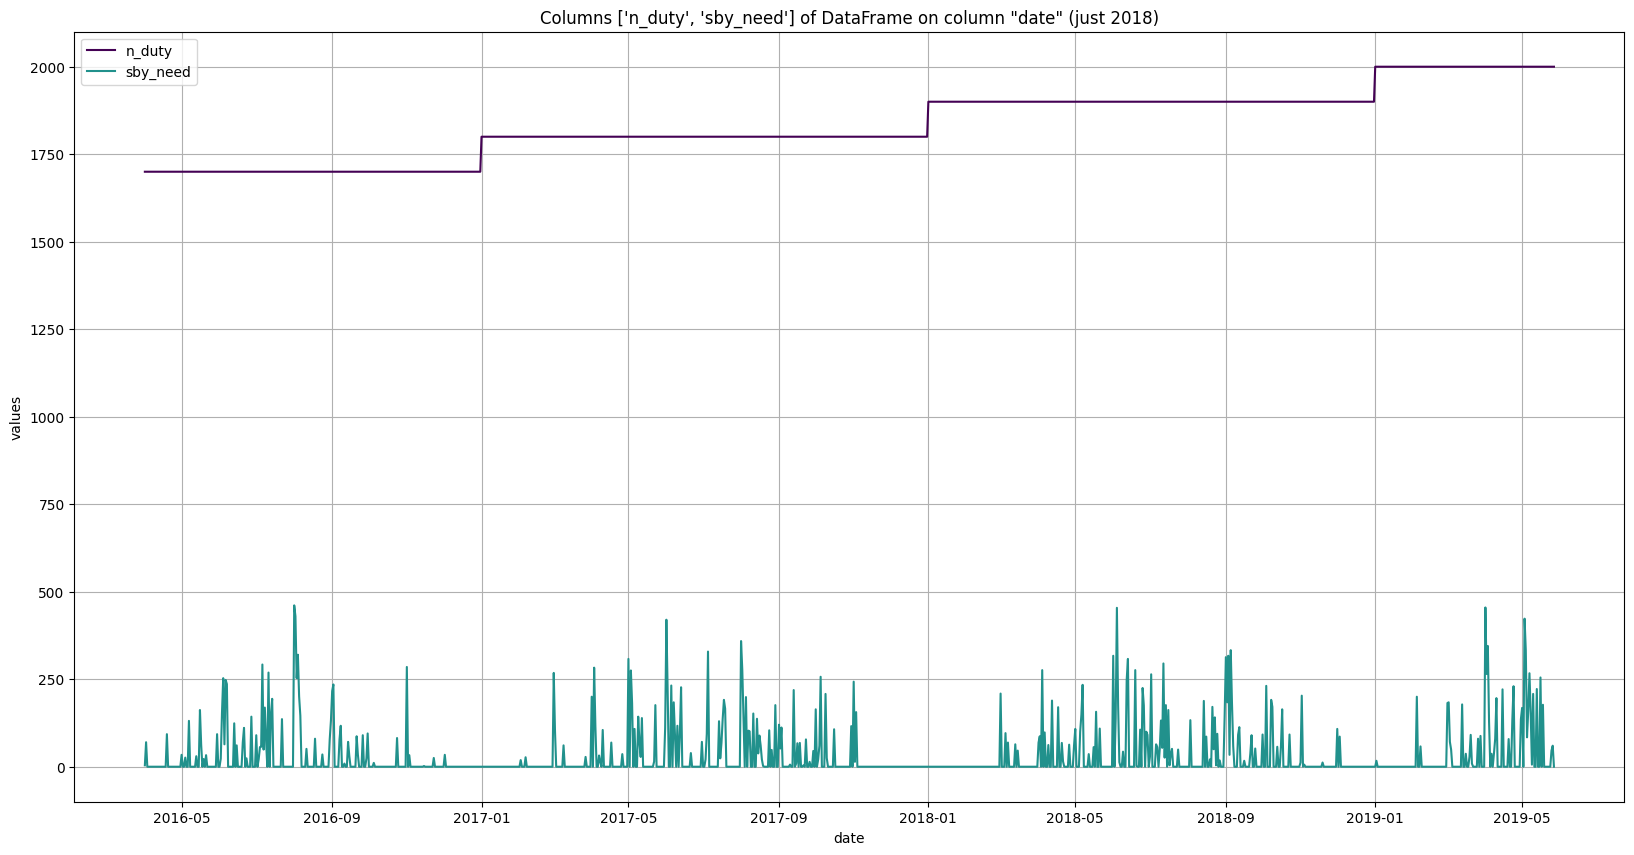

In [10]:

correct_n_duty_and_sby_need = True

if correct_n_duty_and_sby_need:

    # Beheben von n_duty im Jahr 2019
    df.loc['2019':, 'n_duty'] += 100
    df.loc['2019':, 'sby_need'] -= 100
    df['sby_need'] = df['sby_need'].clip(lower=0)

    plot_columns_on_index_in_subplots(df, columns=["n_duty", "sby_need"], annotation=f"just {selected_year}")
    plot_columns_on_index(df, columns=["n_duty", "sby_need"], annotation=f"just {selected_year}")

# Creating new columns from current columns

In [11]:
extended_df = df.copy(deep=True)

# 
extended_df["needed_personal"] = extended_df.apply(lambda row: (row.sby_need + row.n_duty), axis=1)

extended_df["sby_used_percent"] = extended_df.apply(lambda row: (row.sby_need / row.n_sby), axis=1)

extended_df["personal_calculated_by_calls"] = extended_df.apply(lambda row: (row.calls / 4.8), axis=1) 

##############

extended_df["personal_calculated_by_calls_not_below_n_duty"] = extended_df["personal_calculated_by_calls"]

# Filter
mask = (extended_df["personal_calculated_by_calls"] < extended_df["n_duty"])

# Add offset to filtered rows
extended_df.loc[mask, 'personal_calculated_by_calls_not_below_n_duty'] = extended_df.loc[mask, 'n_duty']

############

# 
extended_df["sby_need_calculated_by_calls"] = extended_df.apply(lambda row: row.personal_calculated_by_calls_not_below_n_duty - row.n_duty, axis=1)


#
extended_df["calls_per_duty"] = extended_df.apply(lambda row: row.calls / row.n_duty, axis=1)

#
extended_df["call_stress"] = extended_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need ), axis=1)

display(extended_df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,personal_calculated_by_calls_not_below_n_duty,sby_need_calculated_by_calls,calls_per_duty,call_stress
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1833.333333,90.0,30.182292,16.335938,1.509192e+09,1863.515625,0.335359,1649.902344,1865.947266,32.613932,4.317430,4.238179
std,14.293942,1290.063571,97.759435,0.0,71.753595,53.394089,2.874511e+07,124.273086,0.797262,268.763244,126.744985,76.547170,0.650030,0.541139
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,848.750000,1700.000000,0.000000,2.263333,2.263333
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1453.750000,1800.000000,0.000000,3.860882,3.860882
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1652.500000,1886.875000,0.000000,4.323158,4.323158
75%,78.000000,8827.500000,1900.000000,90.0,0.000000,0.000000,1.534054e+09,1905.250000,0.000000,1839.062500,1912.812500,0.000000,4.800000,4.765372
max,119.000000,11850.000000,2000.000000,90.0,461.000000,465.000000,1.558915e+09,2455.000000,5.122222,2468.750000,2468.750000,495.000000,6.197647,4.896288


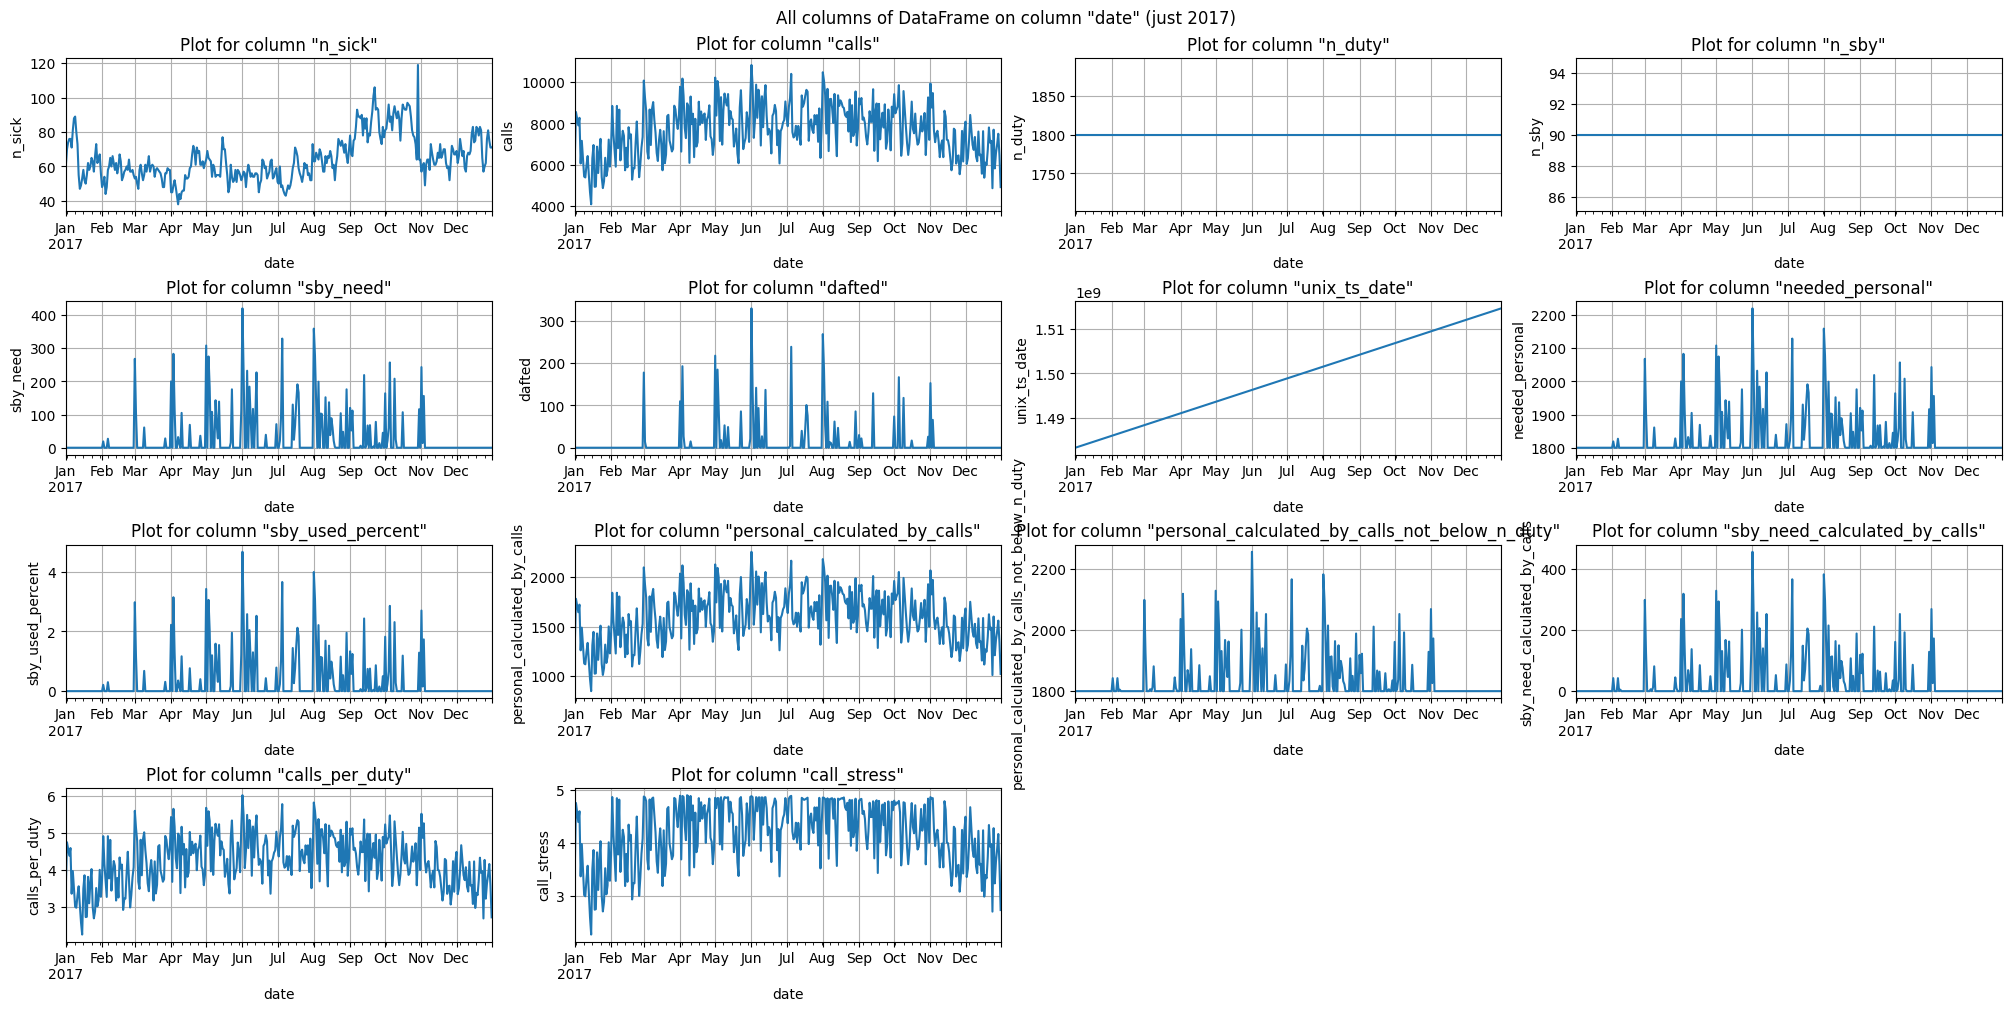

In [12]:
selected_year = 2017

one_year_df = extended_df[extended_df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")

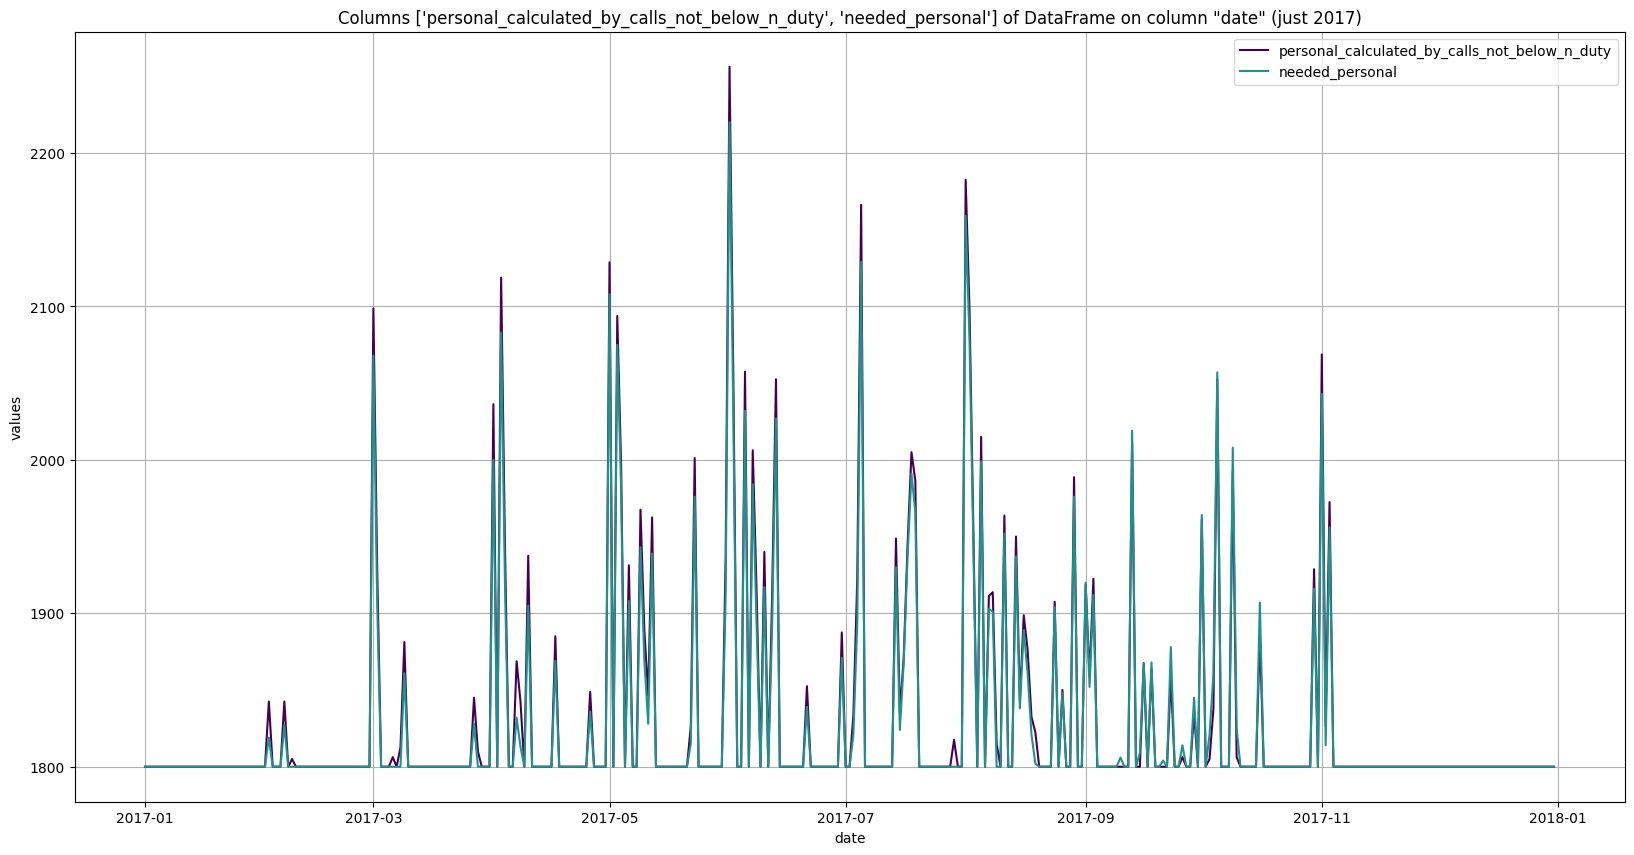

In [13]:
plot_columns_on_index(one_year_df, columns=["personal_calculated_by_calls_not_below_n_duty", "needed_personal"], annotation=f"just {selected_year}")

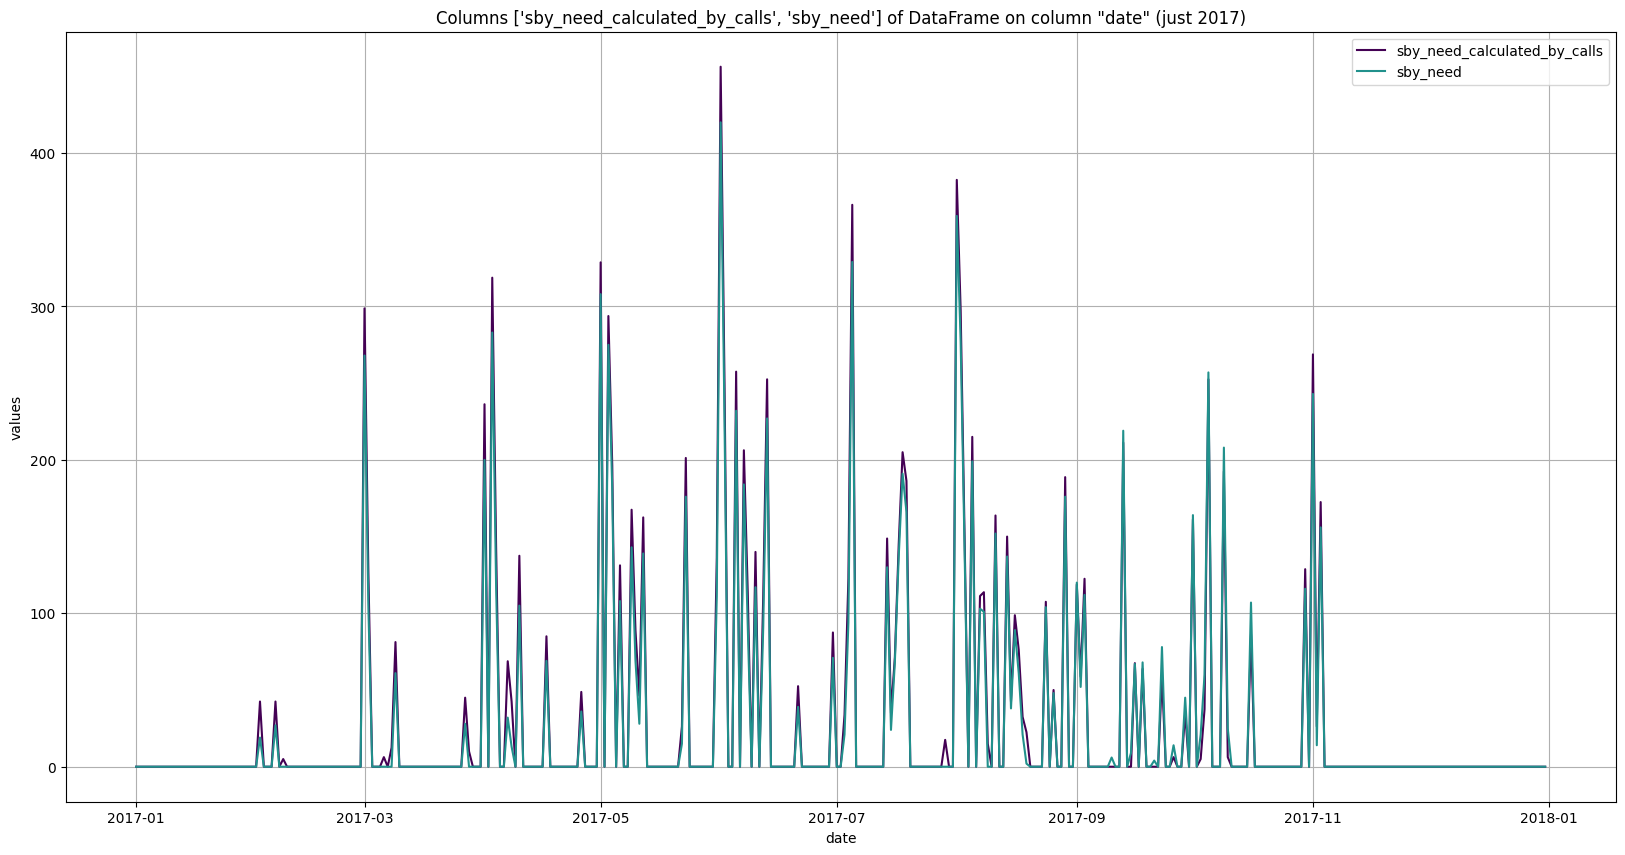

In [14]:
plot_columns_on_index(one_year_df, columns=["sby_need_calculated_by_calls", "sby_need"], annotation=f"just {selected_year}")

## Calculate metrics

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


def calculate_regression_metrics(y_test : List, y_pred : List, print_results : bool = False) -> dict:
    results= {
        'MAE': float(mean_absolute_error(y_test, y_pred)),
        'MSE': float(mean_squared_error(y_test, y_pred)),
        'R2':float( r2_score(y_test, y_pred)),
        'MAPE': float(mean_absolute_percentage_error(y_test, y_pred)),
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

print("For needed_personal over all time:")
calculate_regression_metrics(extended_df["needed_personal"], extended_df["personal_calculated_by_calls_not_below_n_duty"], print_results=True)

print("For sby_need over all time:")
_ = calculate_regression_metrics(extended_df["sby_need"], extended_df["sby_need_calculated_by_calls"], print_results=True)

For needed_personal over all time:
Results: - MAE: 3.609592013888889, MSE: 70.73768446180556, R2: 0.995415691580181, MAPE: 0.0018503171239042352
For sby_need over all time:
Results: - MAE: 3.609592013888889, MSE: 70.73768446180556, R2: 0.9862487978652218, MAPE: 581519483134862.2


### Custom metrics to evaluate task success

In [16]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:
    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

display("Aktueller Stand der Metriken mit festem n_sby:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "n_sby", print_results=False))

display("Stand, wenn man dynamisch aus Calls berechnet:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "sby_need_calculated_by_calls", print_results=False))

'Aktueller Stand der Metriken mit festem n_sby:'

{'Anteil an Tagen mit Unterbesetzung (%)': 13.10763888888889,
 'Anteil an Tagen mit Überbesetzung (%)': 86.63194444444444,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.26041666666666663,
 'Durchschnittliche Überbesetzung': 84.44689378757515,
 'Durchschnittliche Unterbesetzung': 101.7748344370861,
 'Median Überbesetzung': 90.0,
 'Median Unterbesetzung': 85.0}

'Stand, wenn man dynamisch aus Calls berechnet:'

{'Anteil an Tagen mit Unterbesetzung (%)': 6.163194444444445,
 'Anteil an Tagen mit Überbesetzung (%)': 19.618055555555554,
 'Anteil an Tagen mit perfekter Prediction (%)': 74.21875,
 'Durchschnittliche Überbesetzung': 15.39712389380531,
 'Durchschnittliche Unterbesetzung': 9.556338028169014,
 'Median Überbesetzung': 14.5,
 'Median Unterbesetzung': 7.75}

## Findings

Erkenntnisse:
- das benötigte Personal bzw die Einsatzfahrer im Bereitschaftsdienst kann man problemlos über calls berechnen und das mit einem guten R2-Score

To-Do:
- wie bekommt man calls gut predcitet

# Plot calls

## Plot over years

In [17]:
yearly_df = df.copy(deep=True)

target_column_name = "calls"

range_of_years = range(yearly_df.index.year.min(), yearly_df.index.year.max() + 1)

# New column for each year
for year in range_of_years:
    yearly_df[f'year_{year}'] = yearly_df.apply(lambda row: row[target_column_name] if row.name.year == year else None, axis=1)

# Only select yearly columns
yearly_df = yearly_df[[f'year_{year}' for year in range_of_years]]

yearly_df.index = yearly_df.index.day_of_year

display(yearly_df)
display(yearly_df.describe())

,year_2016,year_2017,year_2018,year_2019
date,,,,
92,8154.0,NaN,NaN,NaN
93,8526.0,NaN,NaN,NaN
94,8088.0,NaN,NaN,NaN
95,7044.0,NaN,NaN,NaN
96,7236.0,NaN,NaN,NaN
...,...,...,...,...
143,NaN,NaN,NaN,8544.0
144,NaN,NaN,NaN,8814.0
145,NaN,NaN,NaN,9846.0


,year_2016,year_2017,year_2018,year_2019
count,275.000000,365.000000,365.000000,147.000000
mean,7306.472727,7656.953425,8274.032877,8838.163265
std,1124.147688,1229.558677,1147.060667,1286.484080
min,4692.000000,4074.000000,5334.000000,5760.000000
25%,6492.000000,6816.000000,7518.000000,7884.000000
50%,7272.000000,7638.000000,8268.000000,8934.000000
75%,8157.000000,8592.000000,9120.000000,9777.000000
max,10536.000000,10830.000000,11370.000000,11850.000000


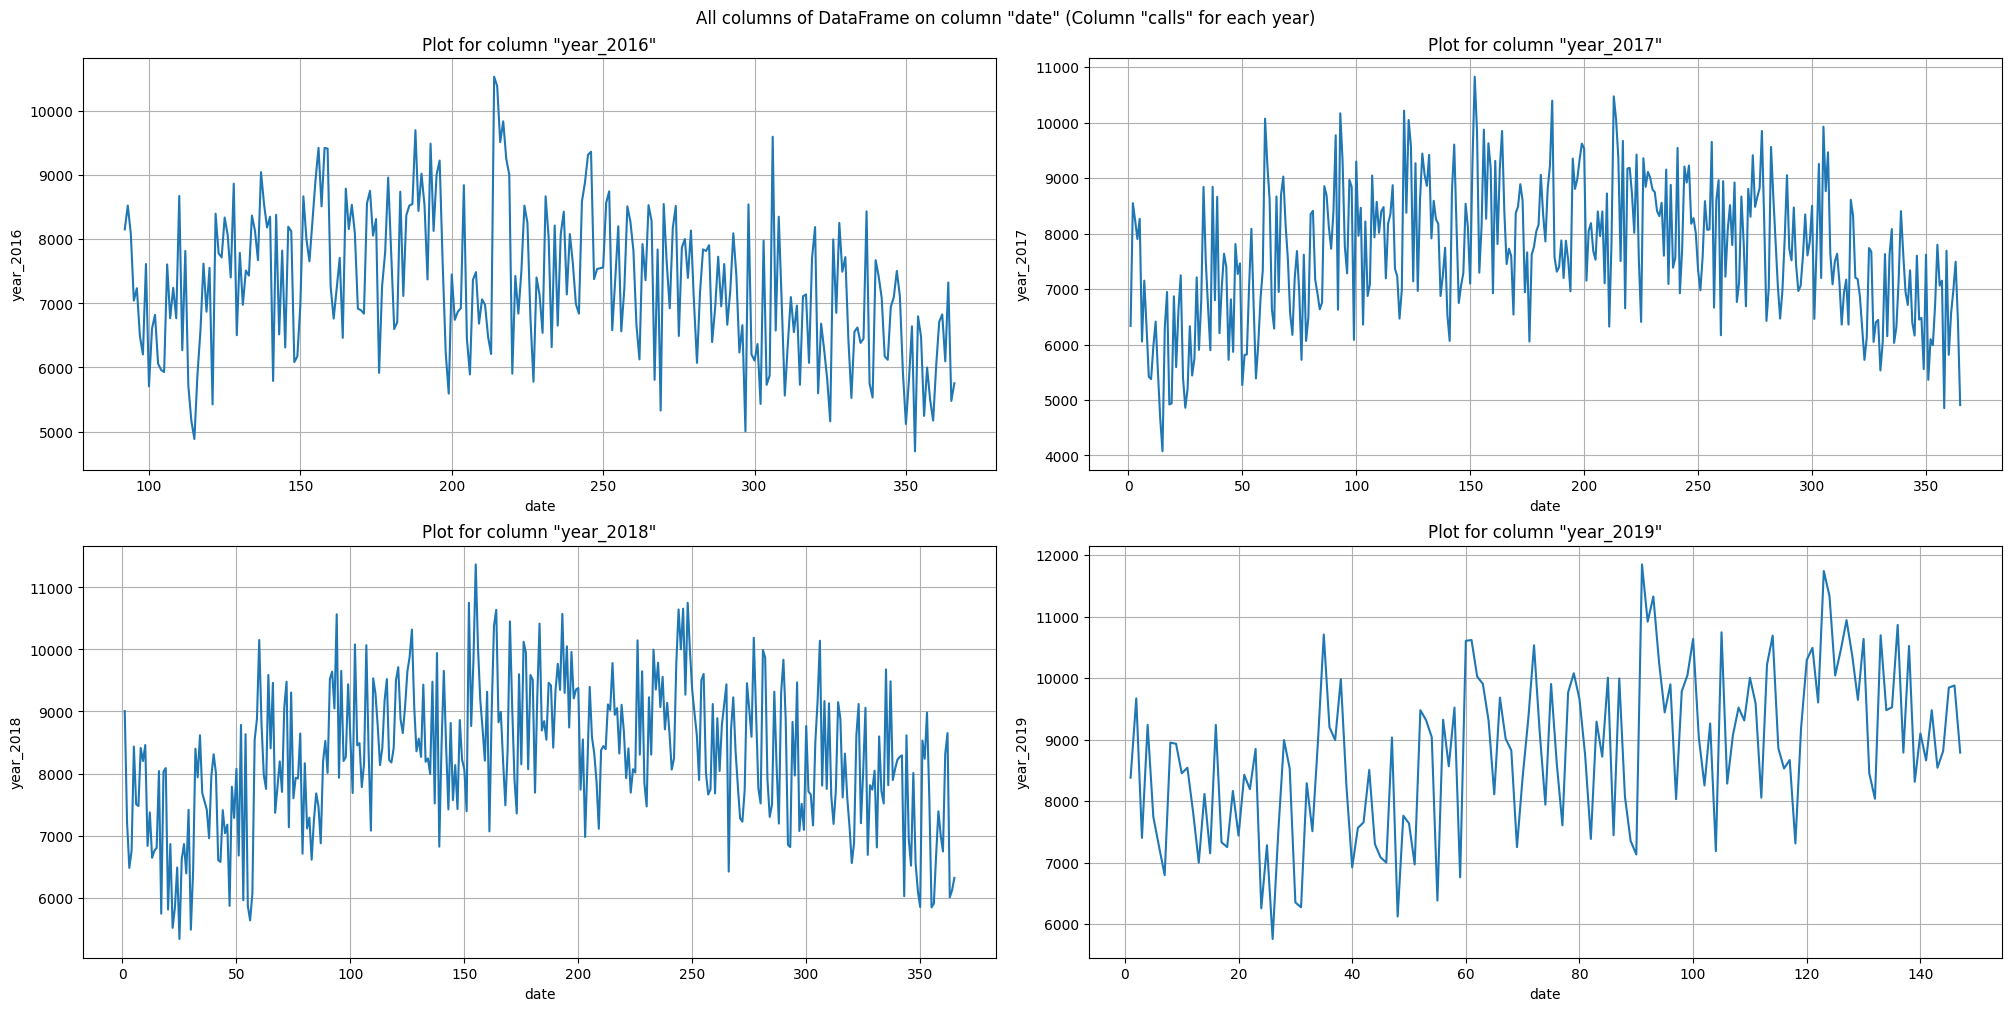

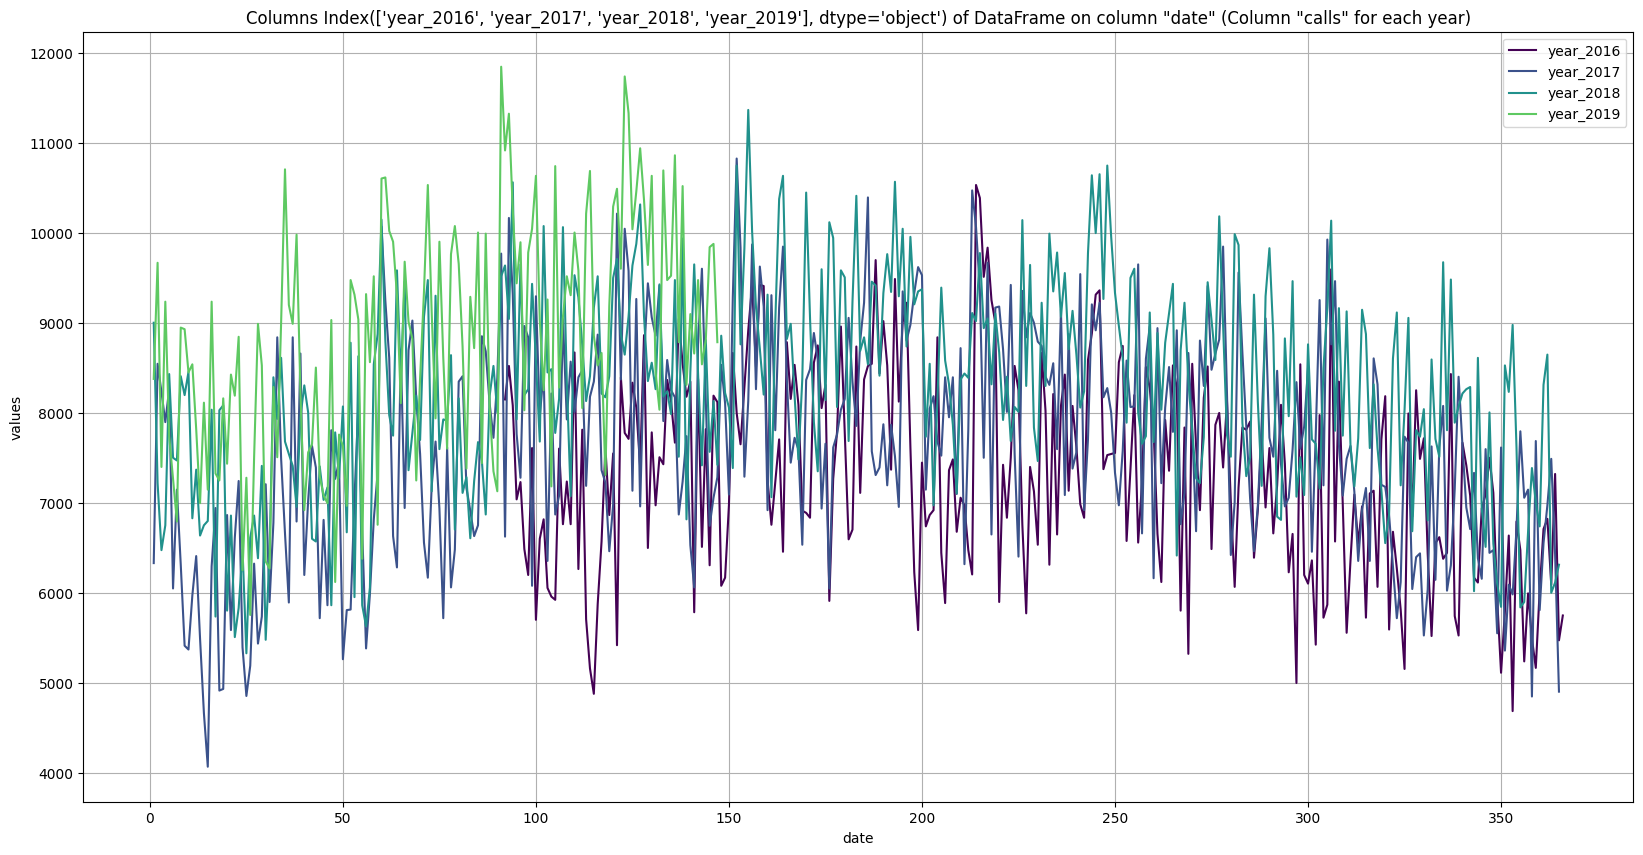

In [18]:
plot_columns_on_index_in_subplots(yearly_df, annotation=f'Column "{target_column_name}" for each year')
plot_columns_on_index(yearly_df, annotation=f'Column "{target_column_name}" for each year')

## Plot over months

In [19]:
selected_year = 2017

monthly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"


# New column for each month 
for month in range(1, 13):
    monthly_df[f'month_{month}'] = monthly_df.apply(lambda row: row[target_column_name] if row.name.month == month else None, axis=1)

# Only select monthly columns
monthly_df = monthly_df[[f'month_{month}' for month in range(1, 13)]]

monthly_df.index = monthly_df.index.day

display(monthly_df)
display(monthly_df.describe())

,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
date,,,,,,,,,,,,
1,6336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6558.0
28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6978.0
29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7494.0


,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
count,31.000000,28.000000,31.000000,30.000000,31.000000,30.000000,31.000000,31.000000,30.00000,31.000000,30.000000,31.000000
mean,6185.806452,6910.928571,7625.612903,8007.400000,8228.129032,8316.000000,8172.193548,8491.161290,8072.40000,7942.451613,7186.600000,6703.354839
std,1122.510562,998.717916,1090.230363,1048.536734,1112.122887,1098.626729,929.351366,1026.315062,887.55618,942.898893,1069.598977,891.576190
min,4074.000000,5268.000000,5724.000000,6084.000000,6066.000000,6054.000000,6324.000000,6408.000000,6168.00000,6426.000000,5532.000000,4854.000000
25%,5409.000000,5970.000000,6696.000000,7203.000000,7191.000000,7630.500000,7527.000000,7584.000000,7399.50000,7131.000000,6360.000000,6129.000000
50%,6054.000000,6819.000000,7620.000000,8100.000000,8256.000000,8214.000000,7956.000000,8748.000000,8127.00000,7854.000000,7149.000000,6714.000000
75%,6909.000000,7471.500000,8514.000000,8776.500000,9168.000000,9145.500000,8805.000000,9180.000000,8773.50000,8583.000000,7647.000000,7416.000000
max,8550.000000,8844.000000,10074.000000,10170.000000,10218.000000,10830.000000,10398.000000,10476.000000,9654.00000,9852.000000,9930.000000,8406.000000


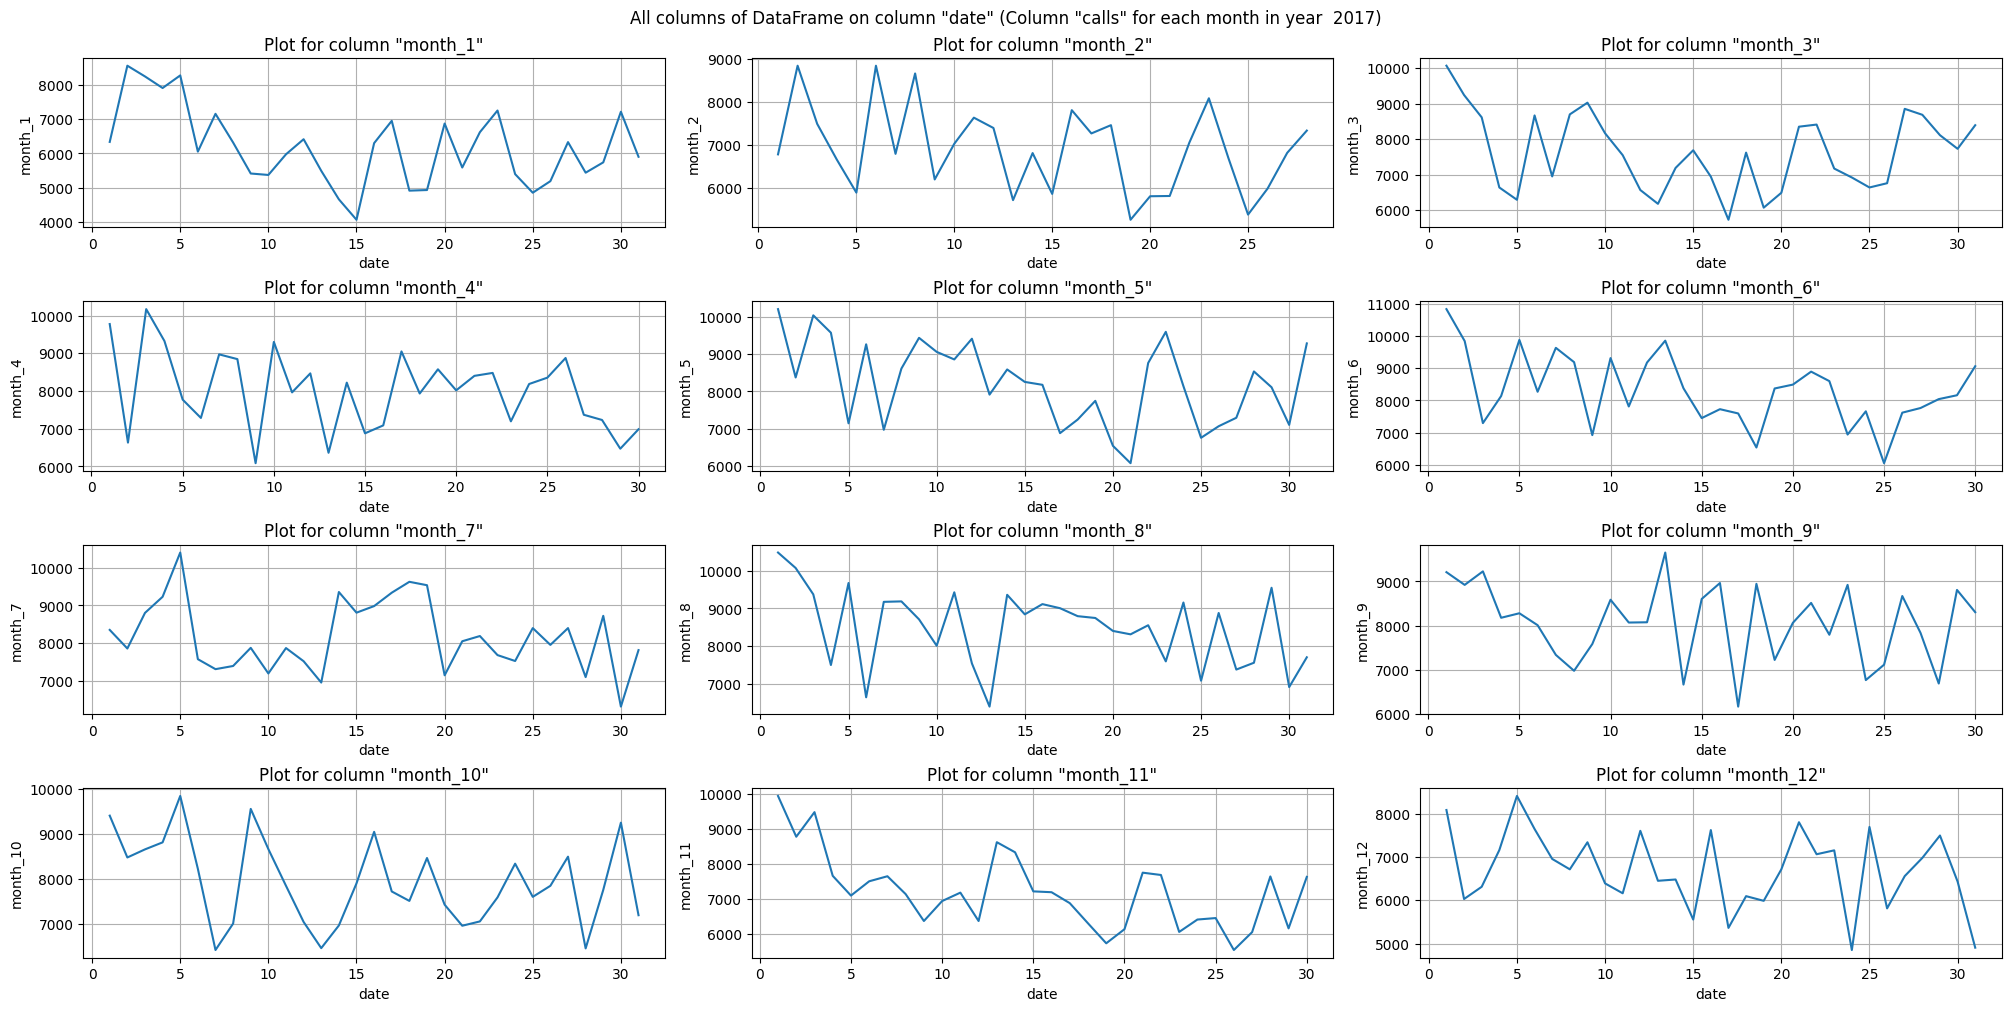

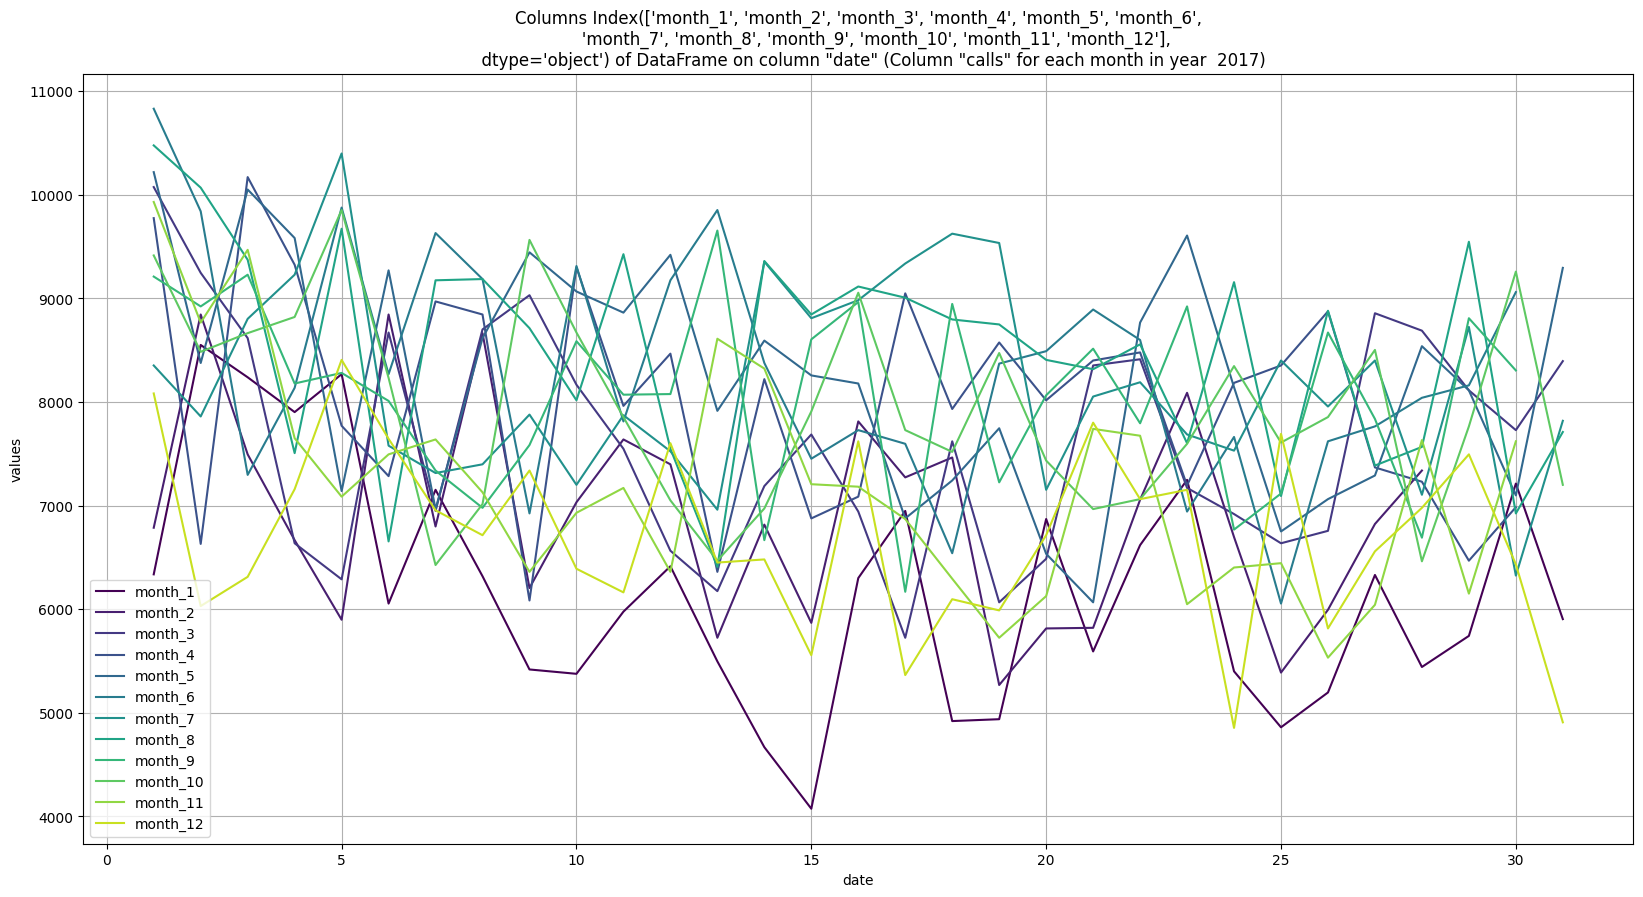

In [20]:
plot_columns_on_index_in_subplots(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')
plot_columns_on_index(monthly_df, annotation=f'Column "{target_column_name}" for each month in year  {selected_year}')

## Findings

Erkenntnisse: 
- bis auf den Winter wenig Seasonalität bei calls erkennbar

## Plot over weeks

In [21]:
selected_year = 2017

weekly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"

numer_of_weeks = df.index.isocalendar().week.max()


# New column for each week 
for week in range(1, numer_of_weeks):
    weekly_df[f'week_{week}'] = weekly_df.apply(lambda row: row[target_column_name] if row.name.isocalendar().week == week else None, axis=1)

# Only select week columns
weekly_df = weekly_df[[f'week_{week}' for week in range(1, numer_of_weeks)]]

weekly_df.index = weekly_df.index.dayofweek

display(weekly_df)
display(weekly_df.describe())

,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
date,,,,,,,,,,,,,,,,,,,,,
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_42,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51
count,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000
mean,7497.428571,5346.000000,6026.571429,5745.428571,6972.000000,7511.142857,6603.428571,6408.000000,7860.000000,7946.571429,...,7747.714286,7733.142857,8479.714286,7011.428571,7172.571429,6566.571429,6838.285714,7229.142857,6462.000000,6523.714286
std,1000.638939,779.291986,874.003596,805.884784,1021.175793,964.473506,982.430805,934.132753,1455.656553,946.966887,...,759.805614,662.390476,1157.314379,503.247738,1028.784859,834.545556,896.845902,660.712602,890.456063,966.737075
min,6054.000000,4074.000000,4920.000000,4860.000000,5898.000000,6204.000000,5268.000000,5388.000000,6288.000000,6564.000000,...,6966.000000,6462.000000,7086.000000,6360.000000,5724.000000,5532.000000,6030.000000,6390.000000,5364.000000,4854.000000
25%,6735.000000,5022.000000,5265.000000,5298.000000,6285.000000,6915.000000,5796.000000,5817.000000,6729.000000,7248.000000,...,7248.000000,7602.000000,7425.000000,6645.000000,6582.000000,6087.000000,6096.000000,6834.000000,5859.000000,6042.000000
50%,7902.000000,5418.000000,6300.000000,5442.000000,6786.000000,7398.000000,6816.000000,5994.000000,7338.000000,8166.000000,...,7518.000000,7764.000000,8766.000000,7128.000000,7182.000000,6402.000000,6312.000000,7158.000000,6450.000000,6714.000000
75%,8253.000000,5736.000000,6744.000000,6036.000000,7353.000000,8151.000000,7368.000000,6876.000000,8931.000000,8685.000000,...,8100.000000,8100.000000,9363.000000,7332.000000,7764.000000,7059.000000,7626.000000,7491.000000,7041.000000,7107.000000
max,8550.000000,6414.000000,6948.000000,7248.000000,8844.000000,8844.000000,7812.000000,8088.000000,10074.000000,9030.000000,...,9054.000000,8502.000000,9930.000000,7638.000000,8610.000000,7740.000000,8082.000000,8406.000000,7620.000000,7800.000000


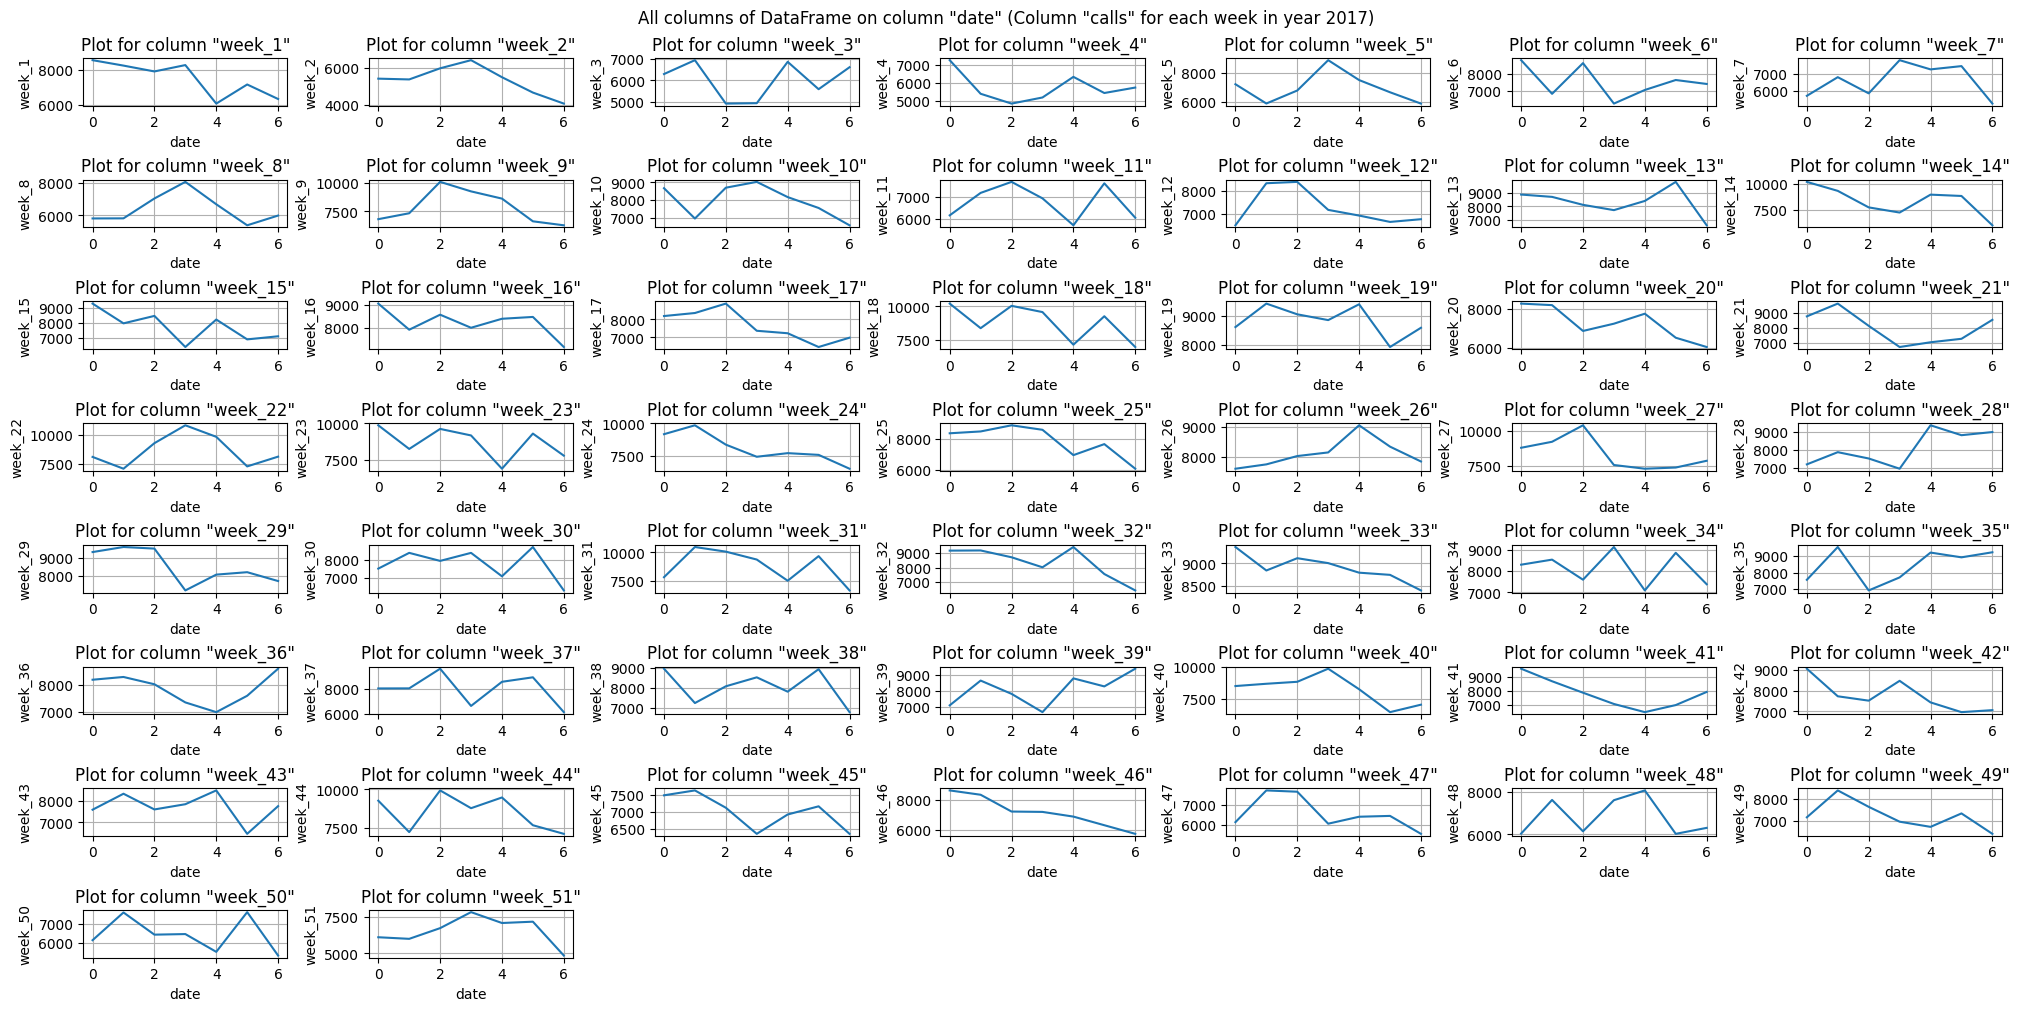

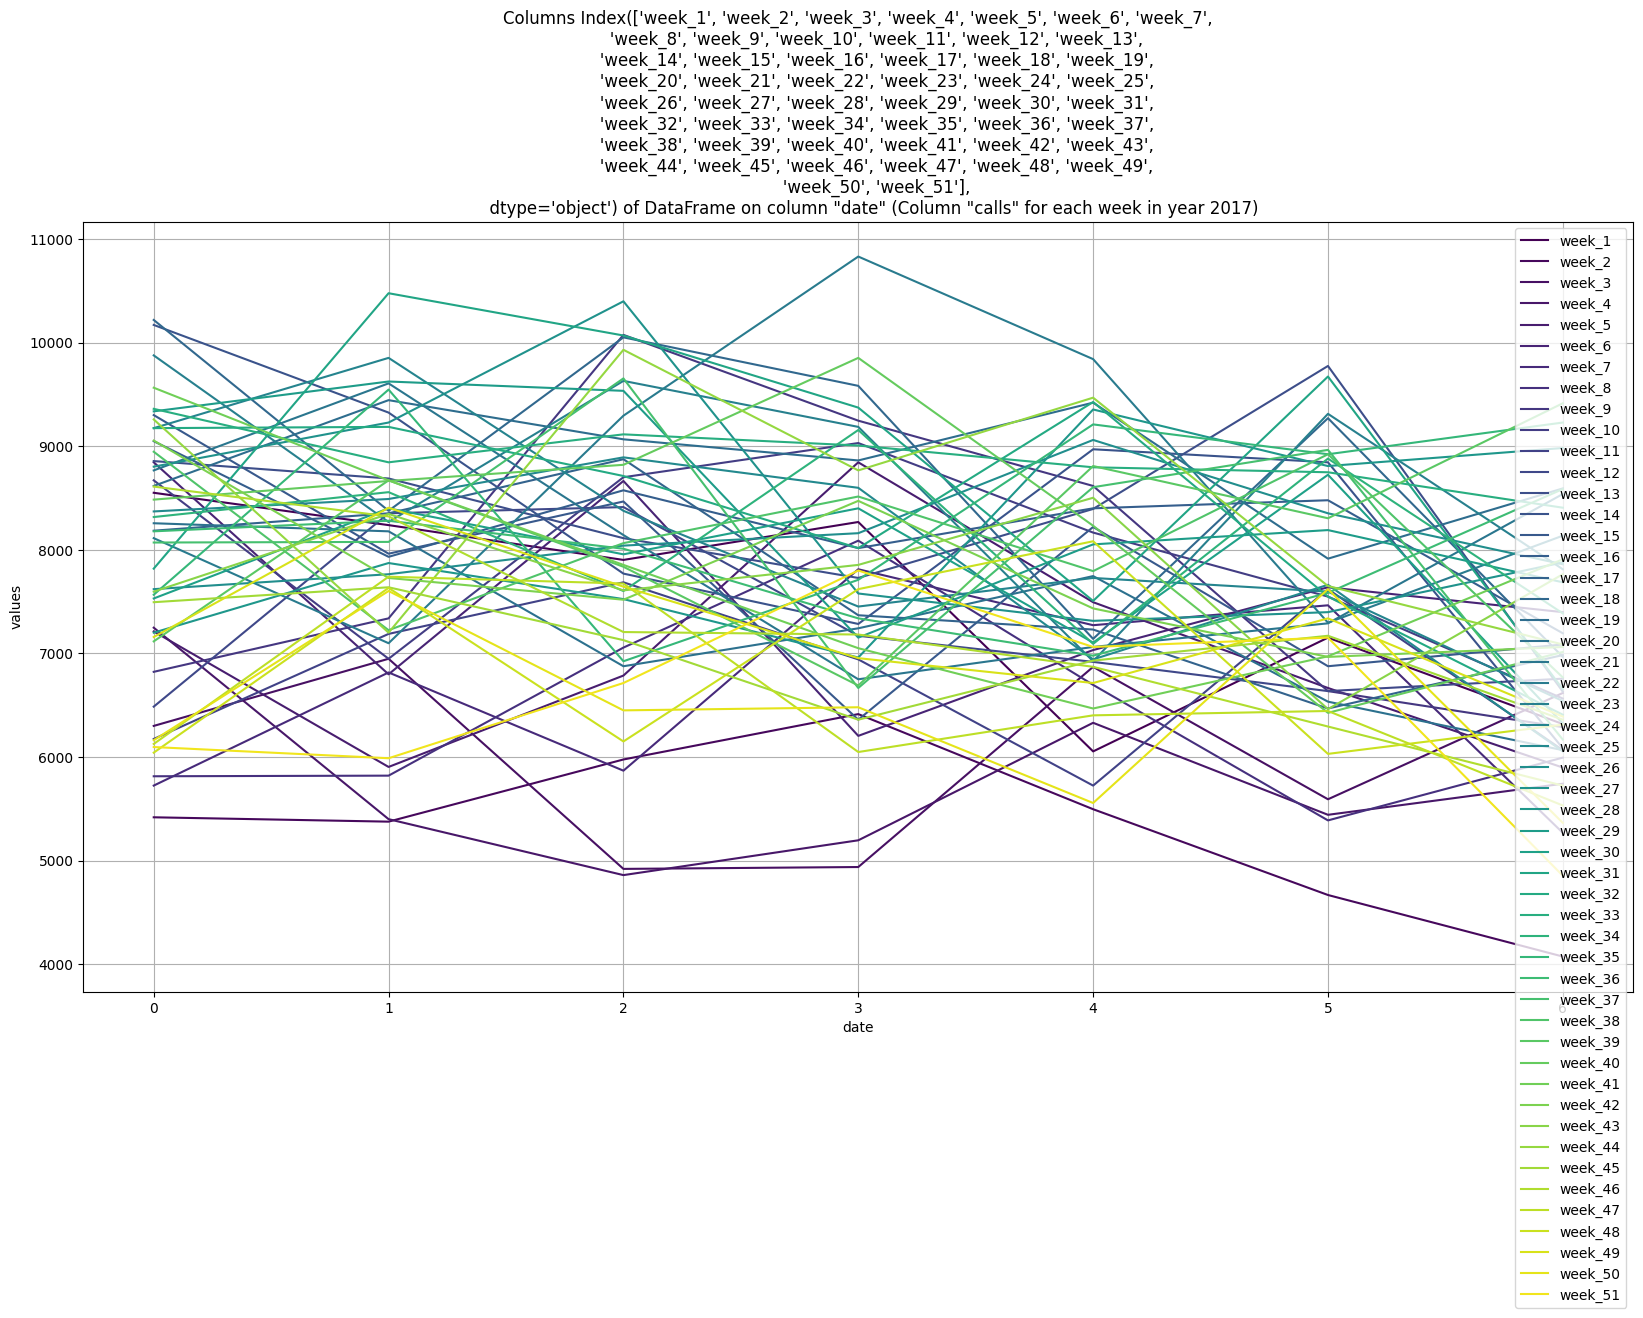

In [22]:
plot_columns_on_index_in_subplots(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')
plot_columns_on_index(weekly_df, annotation=f'Column "{target_column_name}" for each week in year {selected_year}')

## Analyze biggest outlier

In [23]:
display(df[["calls", "sby_need"]].sort_values("calls", ascending=False))

,calls,sby_need
date,,
2019-04-01,11850.0,455.0
2019-05-03,11742.0,423.0
2018-06-04,11370.0,454.0
2019-05-04,11334.0,333.0
2019-04-03,11328.0,345.0
...,...,...
2017-01-25,4860.0,0.0
2017-12-24,4854.0,0.0
2016-12-18,4692.0,0.0


# Add new columns based on date

## Add weekends

In [24]:
if extended_df is None:
    extended_df = df.copy(deep=True)

extended_df['is_weekend'] = extended_df.index.weekday.isin([5, 6]).astype(bool)
extended_df[["is_weekend"]].describe()

,is_weekend
count,1152
unique,2
top,False
freq,822


## Add holidays

In [25]:
import requests

if extended_df is None:
    extended_df = df.copy(deep=True)


range_of_years = range(extended_df.index.year.min(), extended_df.index.year.max() + 1)

german_state = 'BE' # Notfalldienst aus Berlin

holiday_dates = None

# New column for each month 
for year in range_of_years:
    url = f'https://feiertage-api.de/api/?jahr={year}&nur_land={german_state}&nur_daten=1'
    #url = f'https://feiertage-api.de/api/?jahr={year}&nur_daten=1'

    response = requests.get(url)
    holidays = response.json()

    if holiday_dates is None:
        holiday_dates = [pd.to_datetime(datum) for name, datum in holidays.items()]
    else:
        holiday_dates += [pd.to_datetime(datum) for name, datum in holidays.items()]



print("Count of holiday dates:", len(holiday_dates))
extended_df['is_holiday'] = extended_df.index.isin(holiday_dates).astype(bool)
extended_df[["is_holiday"]].describe()


Count of holiday dates: 84


,is_holiday
count,1152
unique,2
top,False
freq,1088


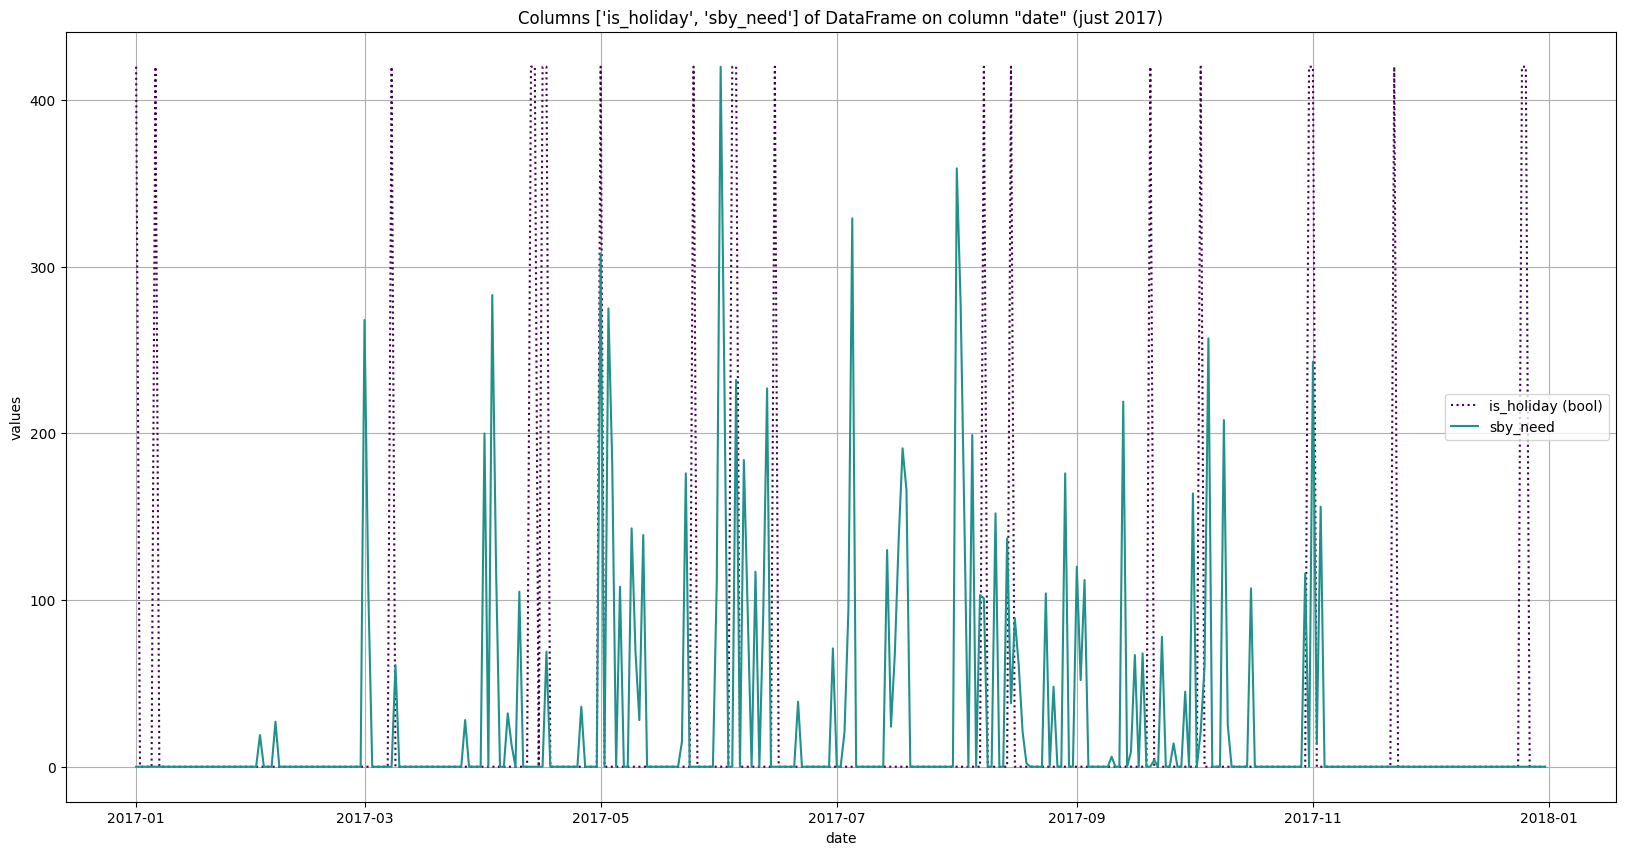

In [26]:
selected_year = 2017

one_year_df = extended_df[extended_df.index.year == selected_year]

one_year_df

plot_columns_on_index(one_year_df, columns=["is_holiday", "sby_need"], annotation=f"just {selected_year}")

## Add temperature

In [27]:
import requests
import pandas as pd
from meteostat import Point, Daily
from datetime import datetime

# Definiere den Standort (Berlin)
berlin = Point(52.5200, 13.4050)

# Definiere den Zeitraum
start = datetime(extended_df.index.year.min(), 1, 1)
end = datetime(extended_df.index.year.max(), 12, 31)

# Lade die Wetterdaten
data = Daily(berlin, start, end)
data = data.fetch()

temperature_columns = ['tavg', "tmin", "tmax"]

# Extrahiere nur die Durchschnittstemperatur
tavg_data = data[temperature_columns]

# To-Do: Evtl mit höchste und Tiefsttemperatur arbeiten

# Füge die Durchschnittstemperatur-Spalte zum DataFrame hinzu
extended_df = extended_df.join(tavg_data, how='left')


In [28]:
extended_df[temperature_columns].describe()

,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000
mean,11.268229,7.051997,15.467882
std,7.711124,6.679351,9.095201
min,-8.800000,-12.800000,-5.800000
25%,5.200000,1.900000,7.900000
50%,10.600000,6.700000,14.950000
75%,17.800000,12.400000,23.000000
max,28.900000,23.900000,38.000000


## Plot new columns

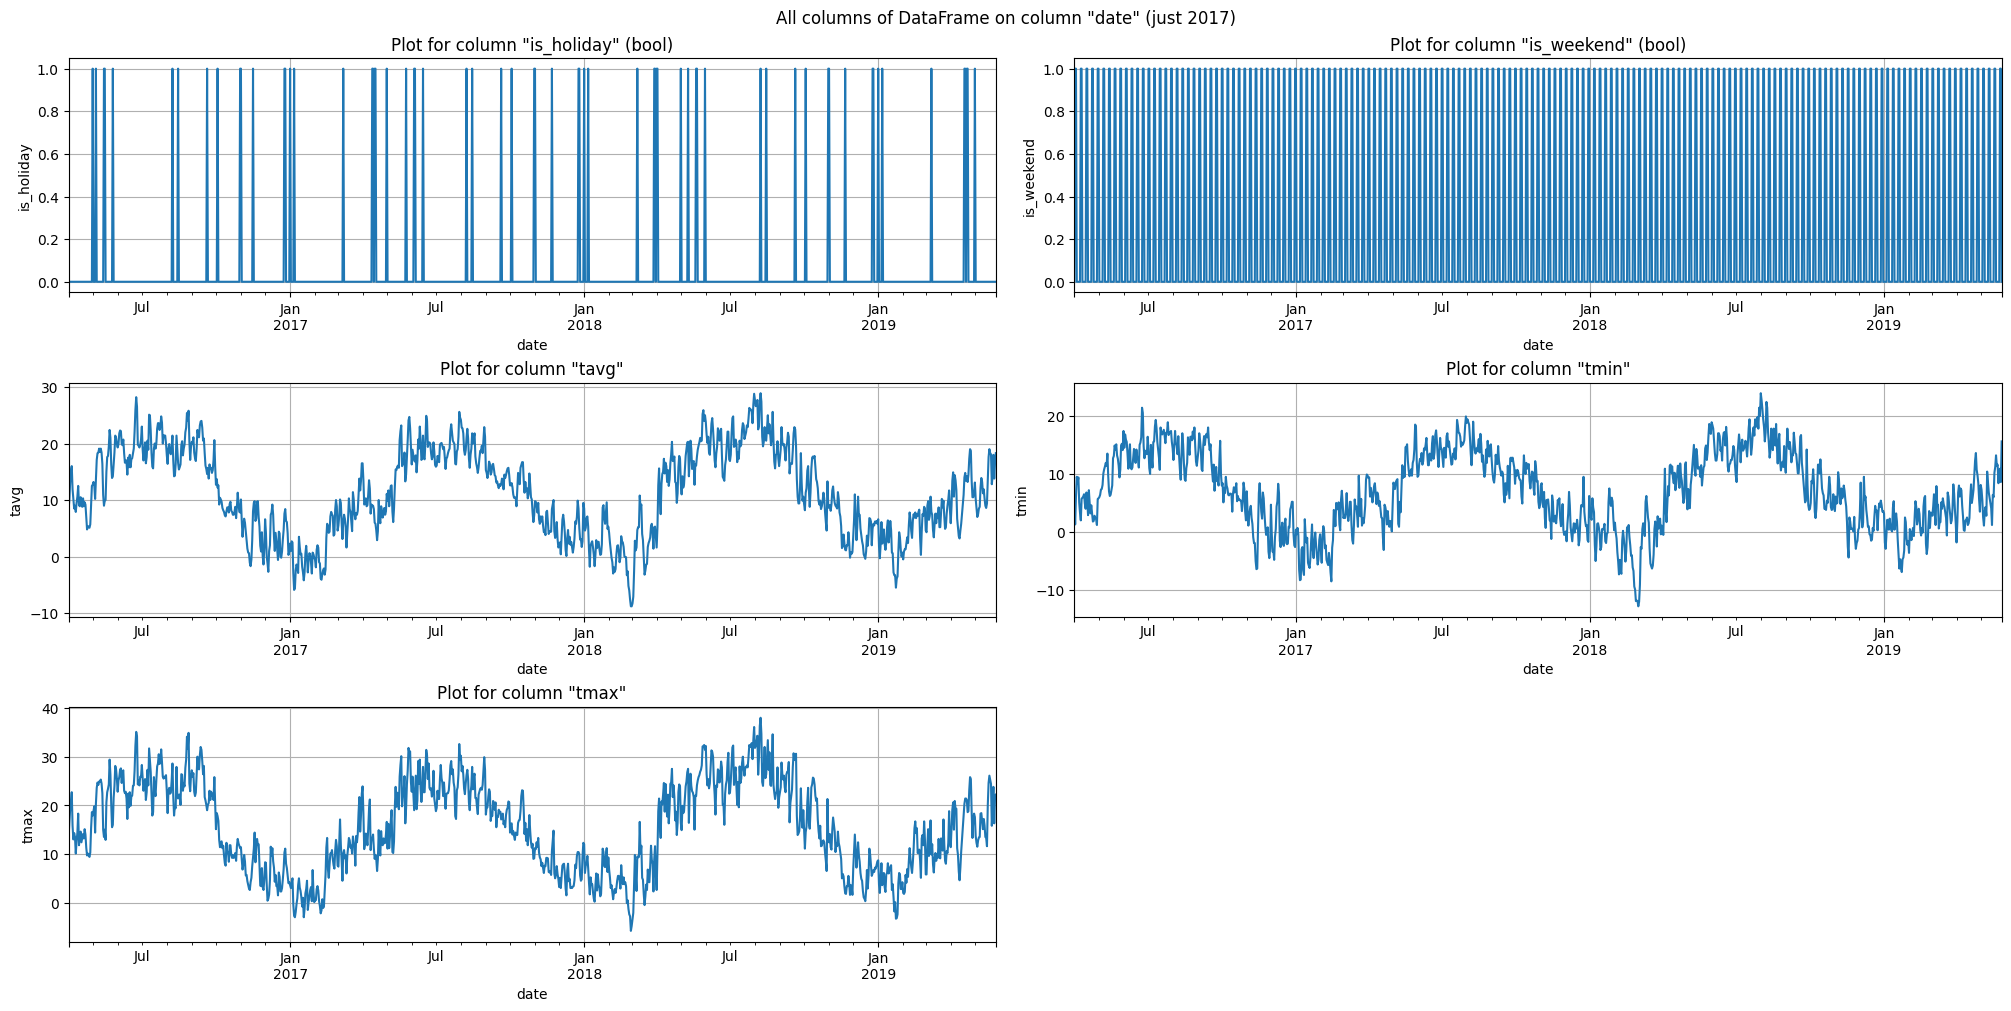

In [29]:
plot_columns_on_index_in_subplots(extended_df, columns=["is_holiday", "is_weekend"] + temperature_columns, annotation=f"just {selected_year}")

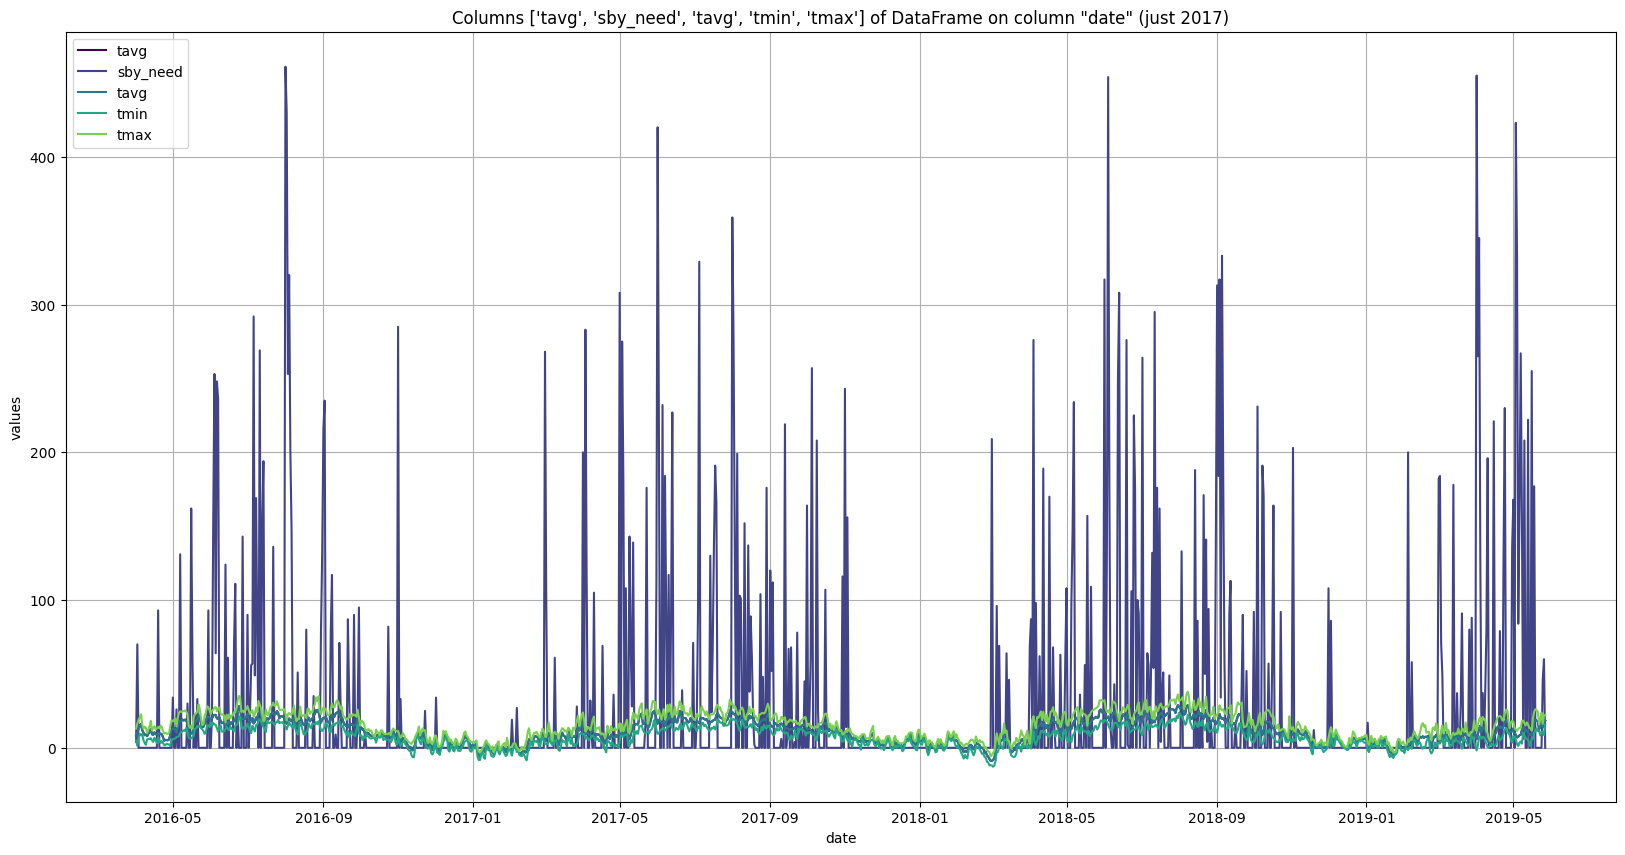

In [30]:
plot_columns_on_index(extended_df, columns=["tavg","sby_need"] + temperature_columns, annotation=f"just {selected_year}")

## Correlation matrix for new features

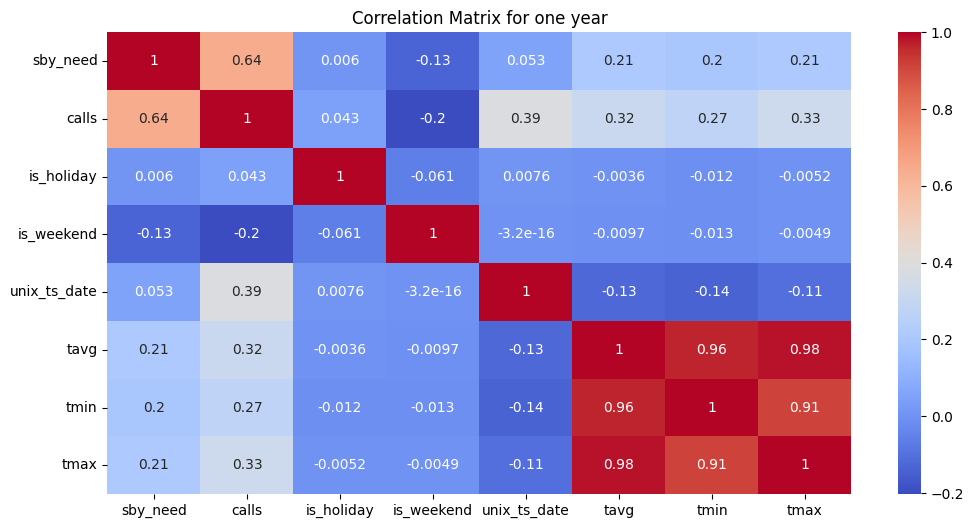

In [31]:

plt.figure(figsize=(12, 6))
sns.heatmap(extended_df[["sby_need", "calls", "is_holiday", "is_weekend", "unix_ts_date"] + temperature_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix for one year')
plt.show()

# Baseline Model

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_column_name = "sby_need"

train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
baseline_pred = train[target_column_name].mean()

test = test.copy()

test['baseline_pred'] = baseline_pred

display(test)

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,baseline_pred
date,,,,,,,,
2018-10-09,97,9870.0,1900,90,171.0,81.0,1539043200,29.994571
2018-10-10,97,7896.0,1900,90,0.0,0.0,1539129600,29.994571
2018-10-11,103,7302.0,1900,90,0.0,0.0,1539216000,29.994571
2018-10-12,106,7506.0,1900,90,0.0,0.0,1539302400,29.994571
2018-10-13,93,9318.0,1900,90,57.0,0.0,1539388800,29.994571
...,...,...,...,...,...,...,...,...
2019-05-23,86,8544.0,2000,90,0.0,0.0,1558569600,29.994571
2019-05-24,81,8814.0,2000,90,0.0,0.0,1558656000,29.994571
2019-05-25,76,9846.0,2000,90,46.0,56.0,1558742400,29.994571


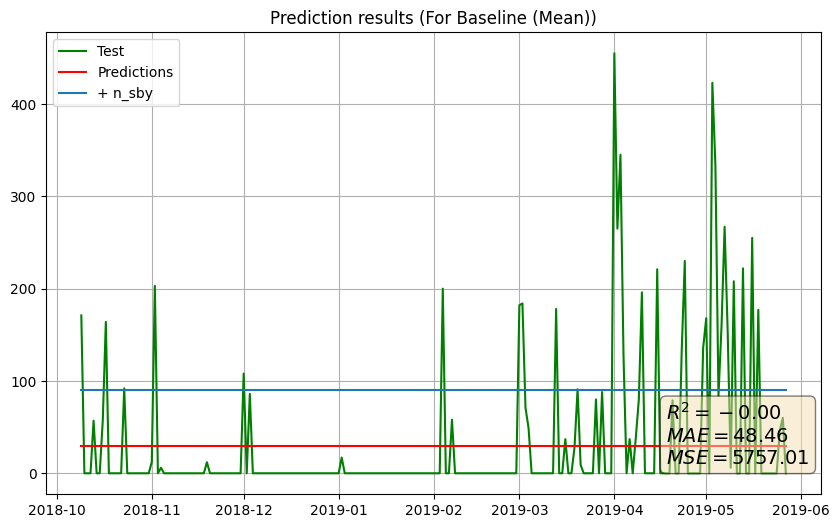

{'Anteil an Tagen mit Unterbesetzung (%)': 19.480519480519483,
 'Anteil an Tagen mit Überbesetzung (%)': 80.51948051948052,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 29.51070015060768,
 'Durchschnittliche Unterbesetzung': 126.7832066594281,
 'Median Überbesetzung': 29.99457111834962,
 'Median Unterbesetzung': 124.00542888165037}

In [33]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$MSE=%.2f$' % (mse, )))

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()


plot_regression_predictions(test[[target_column_name]], test[["baseline_pred"]],  additional_column_df=test[["n_sby"]], annotation="For Baseline (Mean)")

display(calculate_custom_personal_metrics(test, "sby_need", "baseline_pred"))

# Time series analysis

## SARIMAX

In [34]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

target_column_name = 'sby_need'

data = extended_df.copy(deep=True)


train_size = int(len(data) * 0.8)
train, test = data.iloc[:train_size], data.iloc[train_size:]

# Definieren der exogenen Variablen für Training und Test
exog_columns = ['tavg', "tmax"]

exog_train = train[exog_columns]
exog_test = test[exog_columns]


#best params
p, d, q = 2, 0, 2
P, D, Q, s = 1, 0, 0, 3


# Modell mit den besten Parametern trainieren
model = SARIMAX(train[target_column_name], 
                exog=exog_train.astype(float),
                order=(p, d, q), 
                seasonal_order=(P, D, Q, s), 
                enforce_stationarity=False,
                enforce_invertibility=False)
sarimax_result = model.fit(disp=False)

# Vorhersage mit den besten Parametern
forecast = sarimax_result.get_forecast(steps=len(test), exog=exog_test.astype(float))
forecast_ci = forecast.conf_int()

y_pred = forecast.predicted_mean

{'Anteil an Tagen mit Unterbesetzung (%)': 23.809523809523807,
 'Anteil an Tagen mit Überbesetzung (%)': 76.19047619047619,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 17.330499623703904,
 'Durchschnittliche Unterbesetzung': 109.35132822751902,
 'Median Überbesetzung': 15.902212820842959,
 'Median Unterbesetzung': 71.98036067291208}

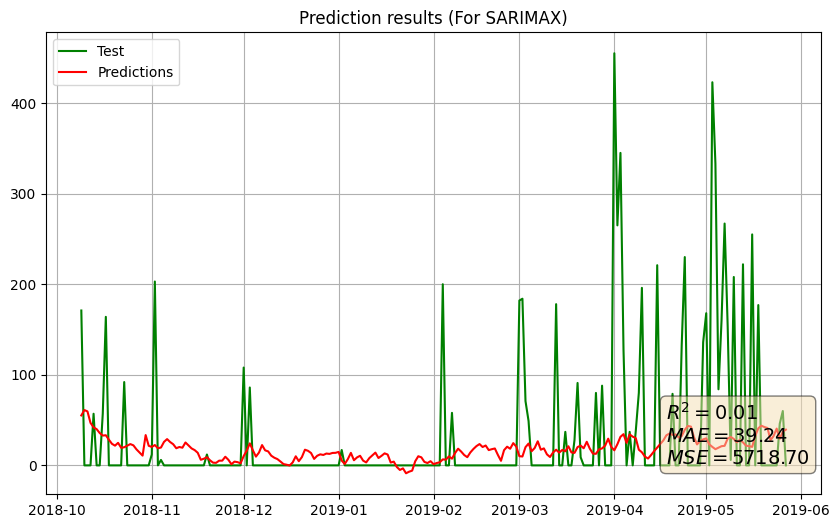

In [35]:

result_df = extended_df[train_size:][["n_duty", "sby_need", "n_sby"]]

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = y_pred
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(test[[target_column_name]], y_pred, annotation="For SARIMAX")

if target_column_name == "calls":
    result_df["predicted_calls"] = y_pred
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(test[[target_column_name]], y_pred, annotation="For SARIMAX (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For SARIMAX (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


In [133]:
regularization_for_underestimation = 5

## LSTM (Long Short-Term Memory)

Epoch 1/20


14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - loss: 0.1275 - val_loss: 0.0895
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0824 - val_loss: 0.0758
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0645 - val_loss: 0.0731
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0809 - val_loss: 0.0726
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0654 - val_loss: 0.0728
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0595 - val_loss: 0.0720
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0679 - val_loss: 0.0727
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0700 - val_loss: 0.0728
Epoch 9/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0529 - val_loss: 0.0737
Epoch 10/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0660 - val_loss: 0.0742
Epoch 11/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0717 - val_loss: 0.0718
Epoch 12/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0603 - val_l

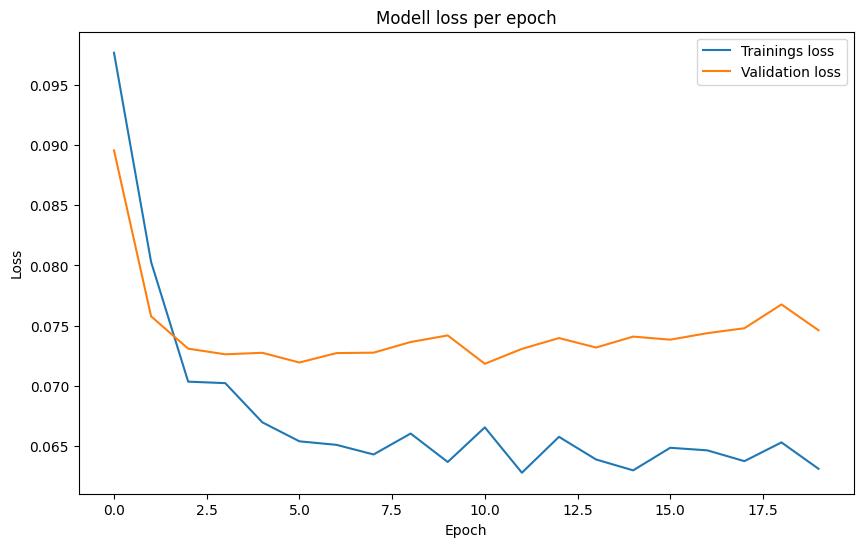

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


In [134]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import LSTM, Dense, Bidirectional, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "sby_need"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.5 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# LSTM-Modell erstellen
model = Sequential()

# V1 LSTM
#model.add(LSTM(units=50, return_sequences=True, input_shape=(seq_length, X_train.shape[2])))
#model.add(LSTM(units=50))

# V2 LSTM
model.add(Bidirectional(LSTM(units=100, return_sequences=True, input_shape=(seq_length, X_train.shape[2]))))
model.add(Dropout(0.2))
model.add(Bidirectional(LSTM(units=100)))
model.add(Dropout(0.2))
######

model.add(Dense(1))

# V1 Modell kompilieren
#model.compile(optimizer='adam', loss='mean_squared_error')

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# V2 Modell kompilieren
# model.compile(optimizer='adam', loss=custom_loss)

# V3 Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])

# Highest R2-Score: 27%


{'Anteil an Tagen mit Unterbesetzung (%)': 14.382402707275805,
 'Anteil an Tagen mit Überbesetzung (%)': 80.5414551607445,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 61.44213717033257,
 'Durchschnittliche Unterbesetzung': 90.71899633819567,
 'Median Überbesetzung': 48.903623320162296,
 'Median Unterbesetzung': 59.85791985690594}

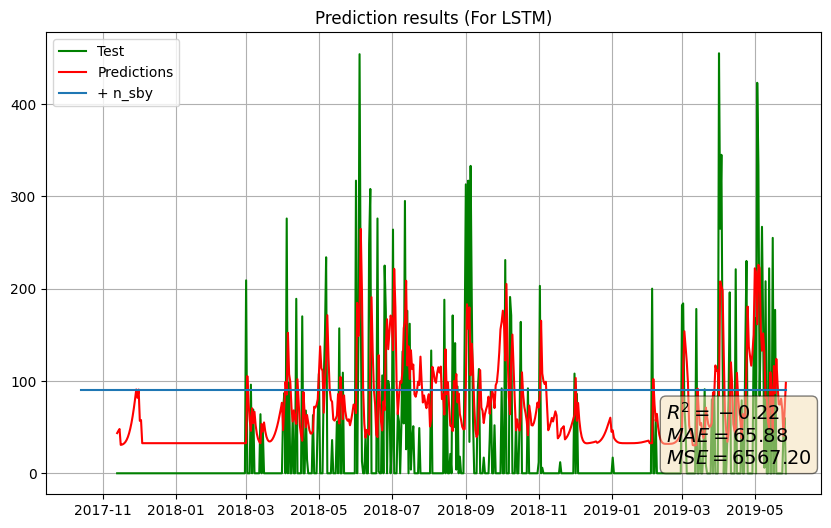

In [135]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For LSTM")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For LSTM (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For LSTM (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

if target_column_name == "needed_personal":
    result_df["predicted_needed_personal"] = predictions

    display(calculate_custom_personal_metrics(result_df, "needed_personal", "predicted_needed_personal"))

    plot_regression_predictions(y_test, predictions, annotation="For LSTM (needed_personal)")


## GRU (Gated Recurrent Unit)

Epoch 1/10


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - loss: 0.0686 - val_loss: 0.1203
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0486 - val_loss: 0.1155
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - loss: 0.0813 - val_loss: 0.1073
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0575 - val_loss: 0.1104
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0568 - val_loss: 0.1076
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0517 - val_loss: 0.1062
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0629 - val_loss: 0.1143
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0664 - val_loss: 0.1105
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - loss: 0.0685 - val_loss: 0.1060
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0602 - val_loss: 0.1038


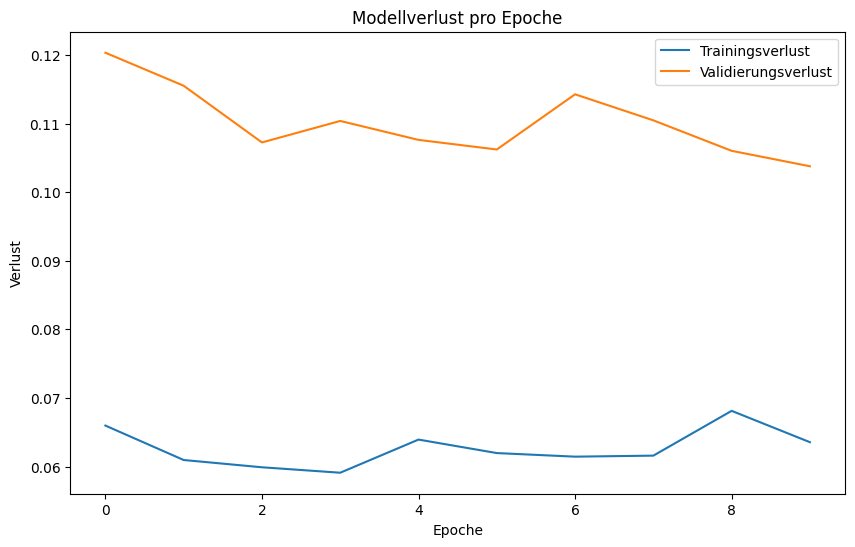

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step


In [138]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import GRU, Dense, Dropout, Bidirectional
import matplotlib.pyplot as plt
import tensorflow as tf


target_column_name = "sby_need"

data = df[[target_column_name]]

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# GRU-Modell erstellen
model = Sequential()
model.add(Bidirectional(GRU(units=200, return_sequences=True, input_shape=(seq_length, 1))))
model.add(Dropout(0.3))
model.add(Bidirectional(GRU(units=200)))
model.add(Dropout(0.3))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen erhöhen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer='adam', loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=10, batch_size=16, validation_split=0.2)

# Plot der Trainings- und Validierungsverluste pro Epoche
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainingsverlust')
plt.plot(history.history['val_loss'], label='Validierungsverlust')
plt.title('Modellverlust pro Epoche')
plt.xlabel('Epoche')
plt.ylabel('Verlust')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

y_test = scaler.inverse_transform(y_test)
y_train = scaler.inverse_transform(y_train)

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])

{'Anteil an Tagen mit Unterbesetzung (%)': 12.549019607843137,
 'Anteil an Tagen mit Überbesetzung (%)': 75.68627450980392,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 64.97051525610098,
 'Durchschnittliche Unterbesetzung': 92.67378187179565,
 'Median Überbesetzung': 49.56212615966797,
 'Median Unterbesetzung': 83.38327026367188}

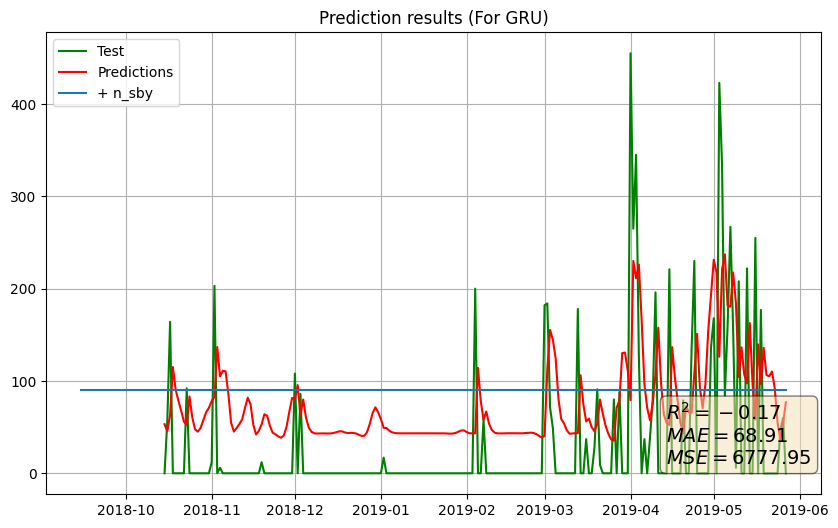

In [139]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":

    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For GRU")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For GRU (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For GRU (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

if target_column_name == "needed_personal":
    result_df["predicted_needed_personal"] = predictions

    display(calculate_custom_personal_metrics(result_df, "needed_personal", "predicted_needed_personal"))

    plot_regression_predictions(y_test, predictions, annotation="For GRU (needed_personal)")



## CNN (Convolutional Neural Networks)

Epoch 1/20


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1654 - val_loss: 0.1511
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0873 - val_loss: 0.1232
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0762 - val_loss: 0.1315
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1010 - val_loss: 0.1393
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0697 - val_loss: 0.1327
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0715 - val_loss: 0.1411
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0827 - val_loss: 0.1508
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0677 - val_loss: 0.1383
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0717 - val_loss: 0.1384
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0824 - val_loss: 0.1587
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0659 - val_loss: 0.1491
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0807 - val_loss: 0.1454


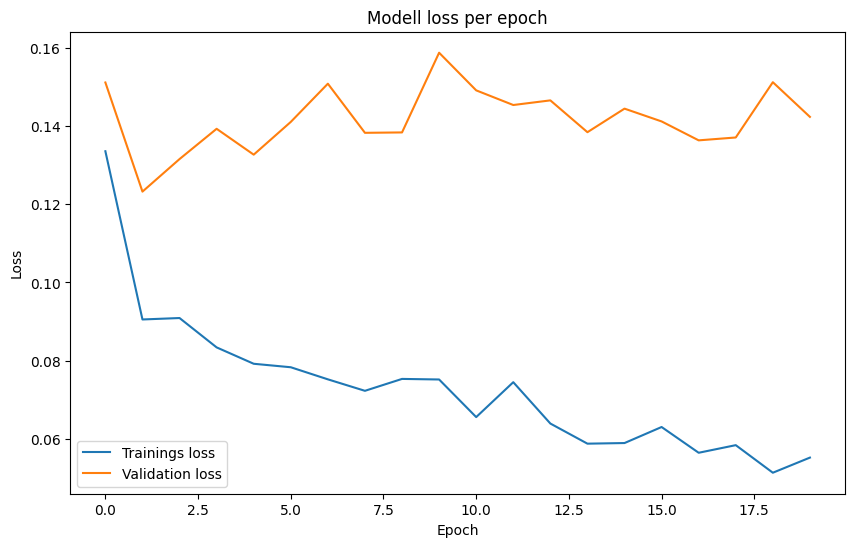

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [102]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Flatten, Dropout, MaxPooling1D
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "sby_need"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# CNN-Modell erstellen
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])



{'Anteil an Tagen mit Unterbesetzung (%)': 13.35149863760218,
 'Anteil an Tagen mit Überbesetzung (%)': 78.4741144414169,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 78.39443908646678,
 'Durchschnittliche Unterbesetzung': 95.36887173590307,
 'Median Überbesetzung': 63.918099991977215,
 'Median Unterbesetzung': 75.98571115732193}

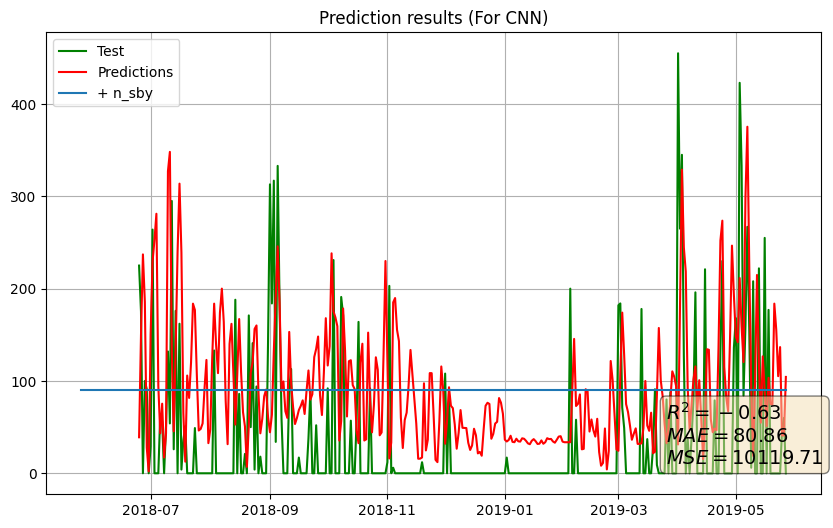

In [103]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For CNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For CNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For CNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## TDNN (Time Delay Neural Network)

Epoch 1/20


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2262 - val_loss: 0.1339
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0865 - val_loss: 0.1198
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0734 - val_loss: 0.1303
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1136 - val_loss: 0.1534
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0864 - val_loss: 0.1285
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0848 - val_loss: 0.1308
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0714 - val_loss: 0.1352
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0728 - val_loss: 0.1478
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0662 - val_loss: 0.1310
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0628 - val_loss: 0.1434
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0641 - val_loss: 0.1435
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0609 - val_loss: 0.1425


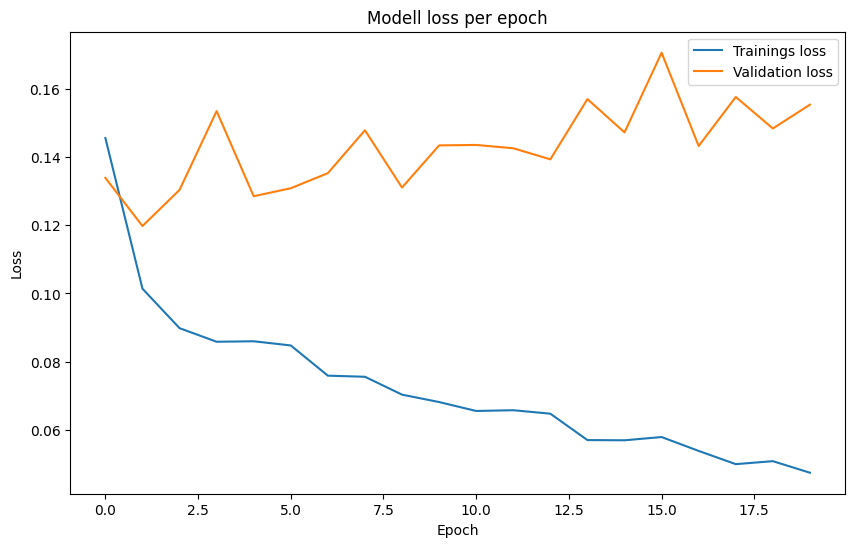

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [104]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Flatten, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "sby_need"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# TDNN-Modell erstellen
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_train.shape[2])))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


{'Anteil an Tagen mit Unterbesetzung (%)': 15.531335149863759,
 'Anteil an Tagen mit Überbesetzung (%)': 75.74931880108991,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.544959128065395,
 'Durchschnittliche Überbesetzung': 70.33813238716785,
 'Durchschnittliche Unterbesetzung': 91.44798434643369,
 'Median Überbesetzung': 51.43362604081631,
 'Median Unterbesetzung': 78.91461104527116}

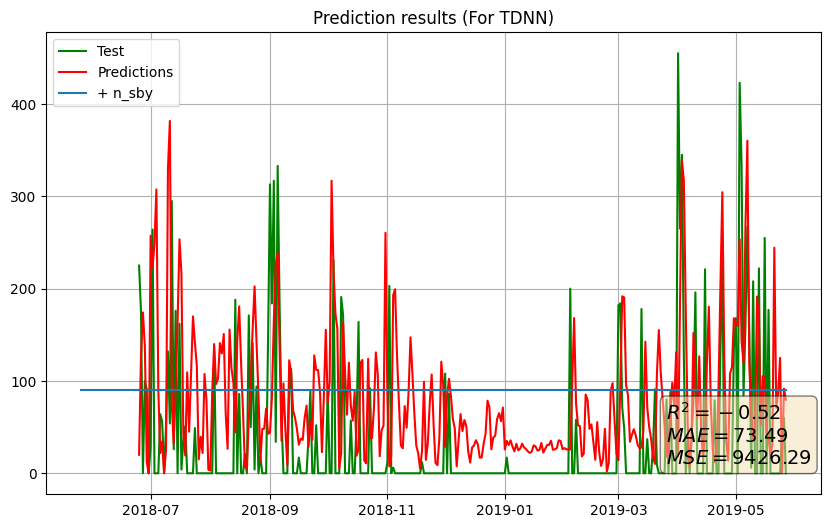

In [105]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For TDNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For TDNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For TDNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## RNN (Recurrent neural network)

Epoch 1/20


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.6229 - val_loss: 0.1743
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2321 - val_loss: 0.1481
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1620 - val_loss: 0.1337
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1728 - val_loss: 0.1316
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1647 - val_loss: 0.1308
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1148 - val_loss: 0.1219
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1187 - val_loss: 0.1312
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1066 - val_loss: 0.1441
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1059 - val_loss: 0.1256
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0953 - val_loss: 0.1276
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1023 - val_loss: 0.1306
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1280 - val_loss: 0.1338

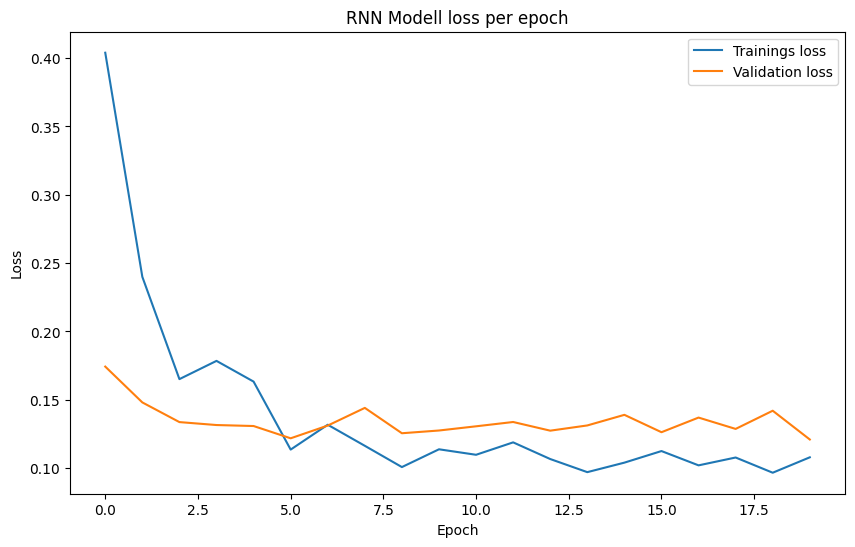

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [106]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import SimpleRNN, Dense, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "sby_need"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN-Modell erstellen
model = Sequential()

model.add(SimpleRNN(units=100, return_sequences=True, input_shape=(seq_length, X_train.shape[2])))
model.add(Dropout(0.2))
model.add(SimpleRNN(units=100))
model.add(Dropout(0.2))

model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('RNN Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


{'Anteil an Tagen mit Unterbesetzung (%)': 9.809264305177113,
 'Anteil an Tagen mit Überbesetzung (%)': 82.01634877384197,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 105.92611776635769,
 'Durchschnittliche Unterbesetzung': 89.53324231557134,
 'Median Überbesetzung': 92.92070817947388,
 'Median Unterbesetzung': 92.04942478239536}

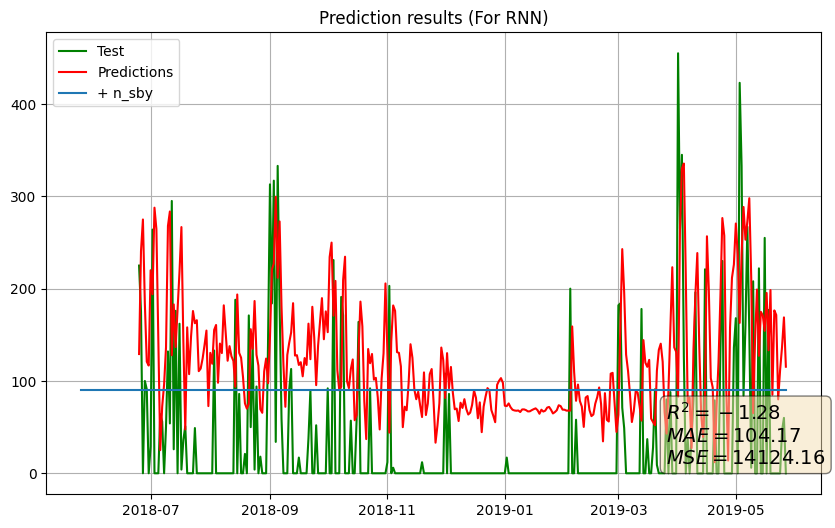

In [107]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For RNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For RNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For RNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## TCN (Temporal Convolutional Network)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 1.5359 - val_loss: 0.2295
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.8837 - val_loss: 0.2663
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.5442 - val_loss: 0.2246
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5197 - val_loss: 0.2136
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.3919 - val_loss: 0.1900
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.3825 - val_loss: 0.2361
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2947 - val_loss: 0.1675
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2466 - val_loss: 0.2047
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2190 - val_loss: 0.1955
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2110 - val_loss: 0.1547
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2678 - val_loss: 0.1708
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2

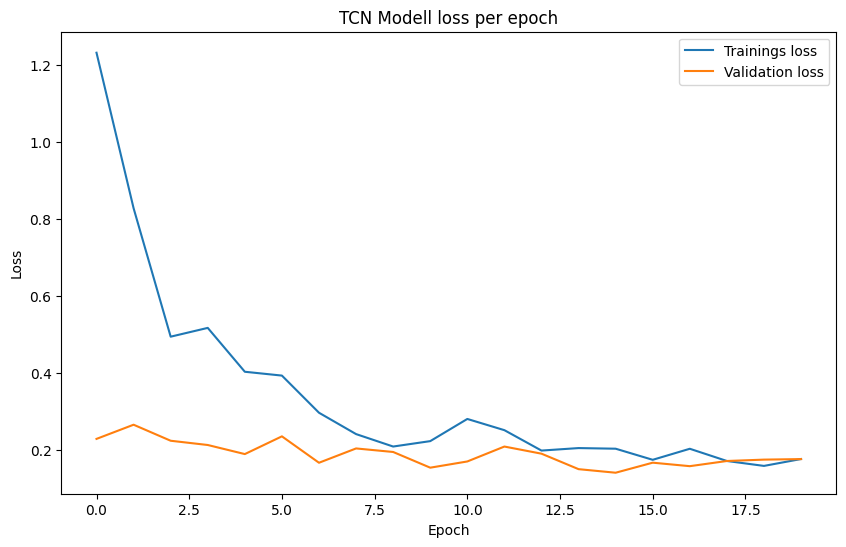

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step


In [108]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Dropout, BatchNormalization, Activation, SpatialDropout1D, Lambda, Add, GlobalAveragePooling1D
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

target_column_name = "sby_need"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.7 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Residual Block für TCN
def residual_block(x, dilation_rate):
    prev_x = x
    for k in range(2):
        x = Conv1D(filters=64, kernel_size=2, padding='causal', dilation_rate=dilation_rate)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)
        x = SpatialDropout1D(0.2)(x)
    prev_x = Conv1D(filters=64, kernel_size=1, padding='same')(prev_x)
    x = Add()([prev_x, x])
    return x

# TCN-Modell erstellen
input_layer = tf.keras.layers.Input(shape=(seq_length, X_train.shape[2]))
x = input_layer
for dilation_rate in [1, 2, 4, 8, 16]:
    x = residual_block(x, dilation_rate)
x = GlobalAveragePooling1D()(x)
output_layer = Dense(1)(x)

model_tcn = tf.keras.models.Model(inputs=input_layer, outputs=output_layer)

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model_tcn.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history_tcn = model_tcn.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history_tcn.history['loss'], label='Trainings loss')
plt.plot(history_tcn.history['val_loss'], label='Validation loss')
plt.title('TCN Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions_tcn = model_tcn.predict(X_test)
predictions_tcn = scaler.inverse_transform(np.concatenate((predictions_tcn, np.zeros((predictions_tcn.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions_tcn = pd.DataFrame(predictions_tcn, index=indices[-len(predictions_tcn):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


{'Anteil an Tagen mit Unterbesetzung (%)': 17.983651226158038,
 'Anteil an Tagen mit Überbesetzung (%)': 73.84196185286103,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 54.05338467608079,
 'Durchschnittliche Unterbesetzung': 109.96693980468042,
 'Median Überbesetzung': 50.68962154537439,
 'Median Unterbesetzung': 96.33368929103017}

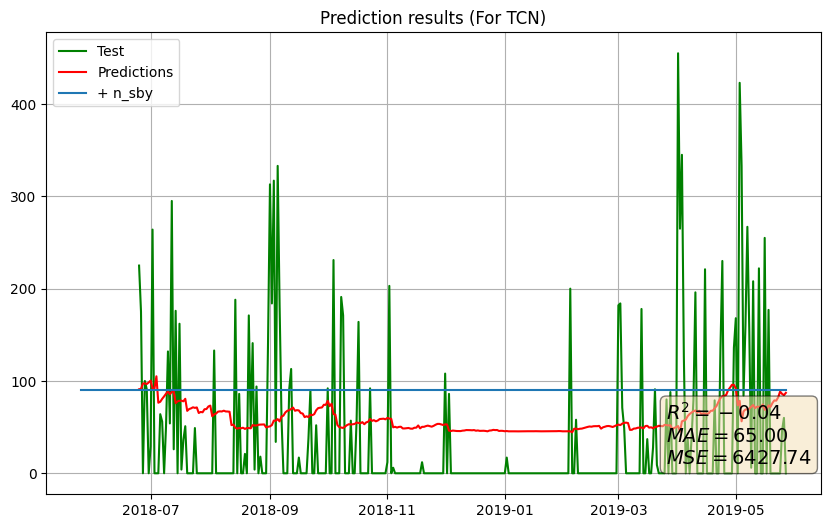

In [109]:

result_df = extended_df[split:][["n_duty", "sby_need", "n_sby"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions_tcn
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions_tcn, additional_column_df=result_df[["n_sby"]], annotation="For TCN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions_tcn
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions_tcn, annotation="For TCN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For TCN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
